# Lab 5: OFDM and Frequency-Domain Equalization
Name: Marc Pham

# Lab 5 Task 1: Deterministic OFDM Transmitter

Complete the OFDM accounting, build the deterministic frame, verify the QPSK and cyclic-prefix round trips, and inspect the supplied frame and resource-grid plots.


In [1]:
from pathlib import Path
import json
import os
import sys
import numpy as np
from IPython.display import Image, display
import IPython.core.pylabtools as pylabtools

# Matplotlib 3.6 expects this compatibility table, which newer IPython omits.
if not hasattr(pylabtools, "backend2gui"):
    pylabtools.backend2gui = {}

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab5_dsp.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 5 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB5_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

import lab5_dsp as lab
import lab5_tools

print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/captures


## OFDM timing and carrier calculations


<span style="color:#165696"><b>Report.</b> Show the timing, carrier, and bit-count calculations. </span>

**Timing Calculations**

Subcarrier spacing $\Delta f=\frac{f_s}{N_{FFT}}=\frac{1{,}000{,}000}{64}=15{,}625\ \text{Hz}$

Useful OFDM symbol duration $T_u=\frac{N_{FFT}}{f_s}=\frac{64}{1{,}000{,}000}=64\ \mu s$

Cyclic prefix (CP) duration $T_{CP}=\frac{N_{CP}}{f_s}=\frac{16}{1{,}000{,}000}=16\ \mu s$

Total OFDM symbol duration $T_{sym}=\frac{N_{FFT}+N_{CP}}{f_s}=\frac{64+16}{1{,}000{,}000}=\frac{80}{1{,}000{,}000}=80\ \mu s$

**Carrier Calculations**

Number of data carriers $N_{data}=N_{active}-N_{pilot}=52-4=48$

Signed-carrier to array-index mapping $i=k \bmod 64$

$-26\rightarrow38,\ -21\rightarrow43,\ -1\rightarrow63,\ 1\rightarrow1,\ 21\rightarrow21,\ 26\rightarrow26$

**Bit-Count Calculations**

Bits per OFDM payload symbol (QPSK) $\text{Bits/symbol}=48\times2=96\ \text{bits}$

Bits per frame $\text{Bits/frame}=20\times96=1920\ \text{bits}$

In [6]:
sample_rate_sps = 1_000_000
nfft = 64
ncp = 16
active_carriers = 52
pilot_carriers = 4
payload_symbols = 20

# Derived quantities
subcarrier_spacing_hz = sample_rate_sps / nfft
useful_symbol_seconds = nfft / sample_rate_sps
cp_seconds = ncp / sample_rate_sps
total_symbol_seconds = (nfft + ncp) / sample_rate_sps

data_carriers = active_carriers - pilot_carriers
bits_per_payload_symbol = data_carriers * 2   # QPSK = 2 bits/carrier
bits_per_frame = payload_symbols * bits_per_payload_symbol

signed_examples = (-26, -21, -1, 1, 21, 26)
array_indices = {k: k % nfft for k in signed_exampçles}

print("subcarrier spacing (Hz):", subcarrier_spacing_hz)
print("useful, CP, total durations (us):",
      1e6*useful_symbol_seconds,
      1e6*cp_seconds,
      1e6*total_symbol_seconds)
print("data carriers, bits/symbol, bits/frame:",
      data_carriers,
      bits_per_payload_symbol,
      bits_per_frame)
print("signed carrier to array index:", array_indices)

subcarrier spacing (Hz): 15625.0
useful, CP, total durations (us): 64.0 16.0 80.0
data carriers, bits/symbol, bits/frame: 48 96 1920
signed carrier to array index: {-26: 38, -21: 43, -1: 63, 1: 1, 21: 21, 26: 26}


In [7]:
assert subcarrier_spacing_hz == 15_625
assert np.isclose(useful_symbol_seconds, 64e-6)
assert np.isclose(cp_seconds, 16e-6)
assert np.isclose(total_symbol_seconds, 80e-6)
assert data_carriers == 48
assert bits_per_payload_symbol == 96
assert bits_per_frame == 1920
assert array_indices == {-26: 38, -21: 43, -1: 63, 1: 1, 21: 21, 26: 26}
print("Task 1 calculations passed.")


Task 1 calculations passed.


## Construct and verify the frame


<span style="color:#165696"><b>Report.</b> Report scale, PAPR, ideal BER, EVM, grid error, and null-carrier error. </span>

In [9]:
reference = lab.build_reference_frame(sequence_number=0)
ideal = lab.ideal_round_trip(reference)
payload_cp = lab.ofdm_modulate(reference.payload_grid, reference.ncp)
recovered_grid = lab.ofdm_demodulate(payload_cp, reference.ncp)

print("active frame samples:", reference.active_frame_length)
print("logical period samples:", reference.logical_period.size)
print("TX scale:", reference.tx_scale)
print("PAPR (dB):", reference.papr_db)
print("ideal results:", ideal)
print("maximum CP-copy error:", np.max(np.abs(payload_cp[:, :ncp] - payload_cp[:, -ncp:])))


active frame samples: 2080
logical period samples: 8192
TX scale: 0.043817606374807375
PAPR (dB): 8.134155266966252
ideal results: {'ber': 0.0, 'bit_errors': 0, 'evm_rms': 1.597252441496604e-16, 'max_grid_error': 5.026748538604307e-16, 'max_null': 5.026748538604307e-16}
maximum CP-copy error: 0.0


In [10]:
assert reference.active_frame_length == 2080
assert reference.logical_period.size == 8192
assert np.max(np.abs(reference.tx_period)) <= 0.1000001
assert np.allclose(recovered_grid, reference.payload_grid, atol=4e-7)
assert ideal["bit_errors"] == 0
print("Deterministic frame checks passed.")


Deterministic frame checks passed.


## Supplied plots


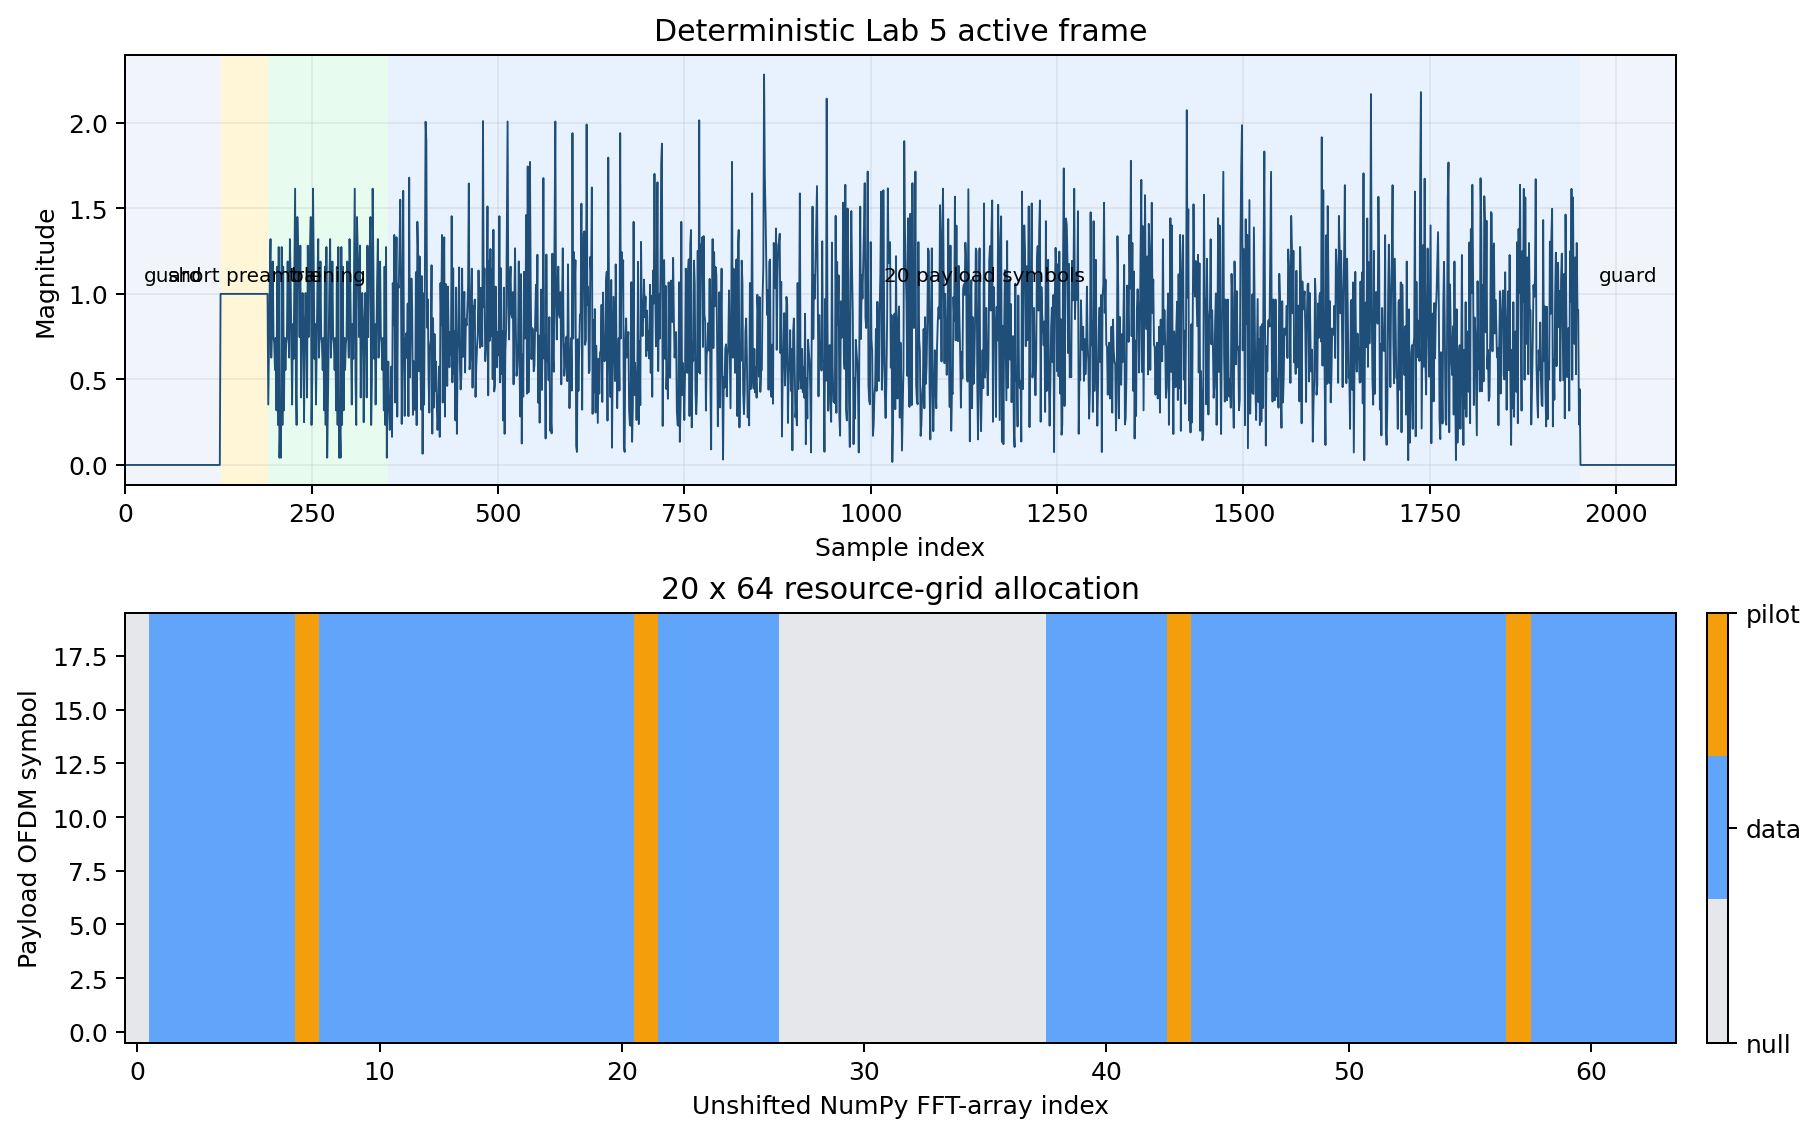

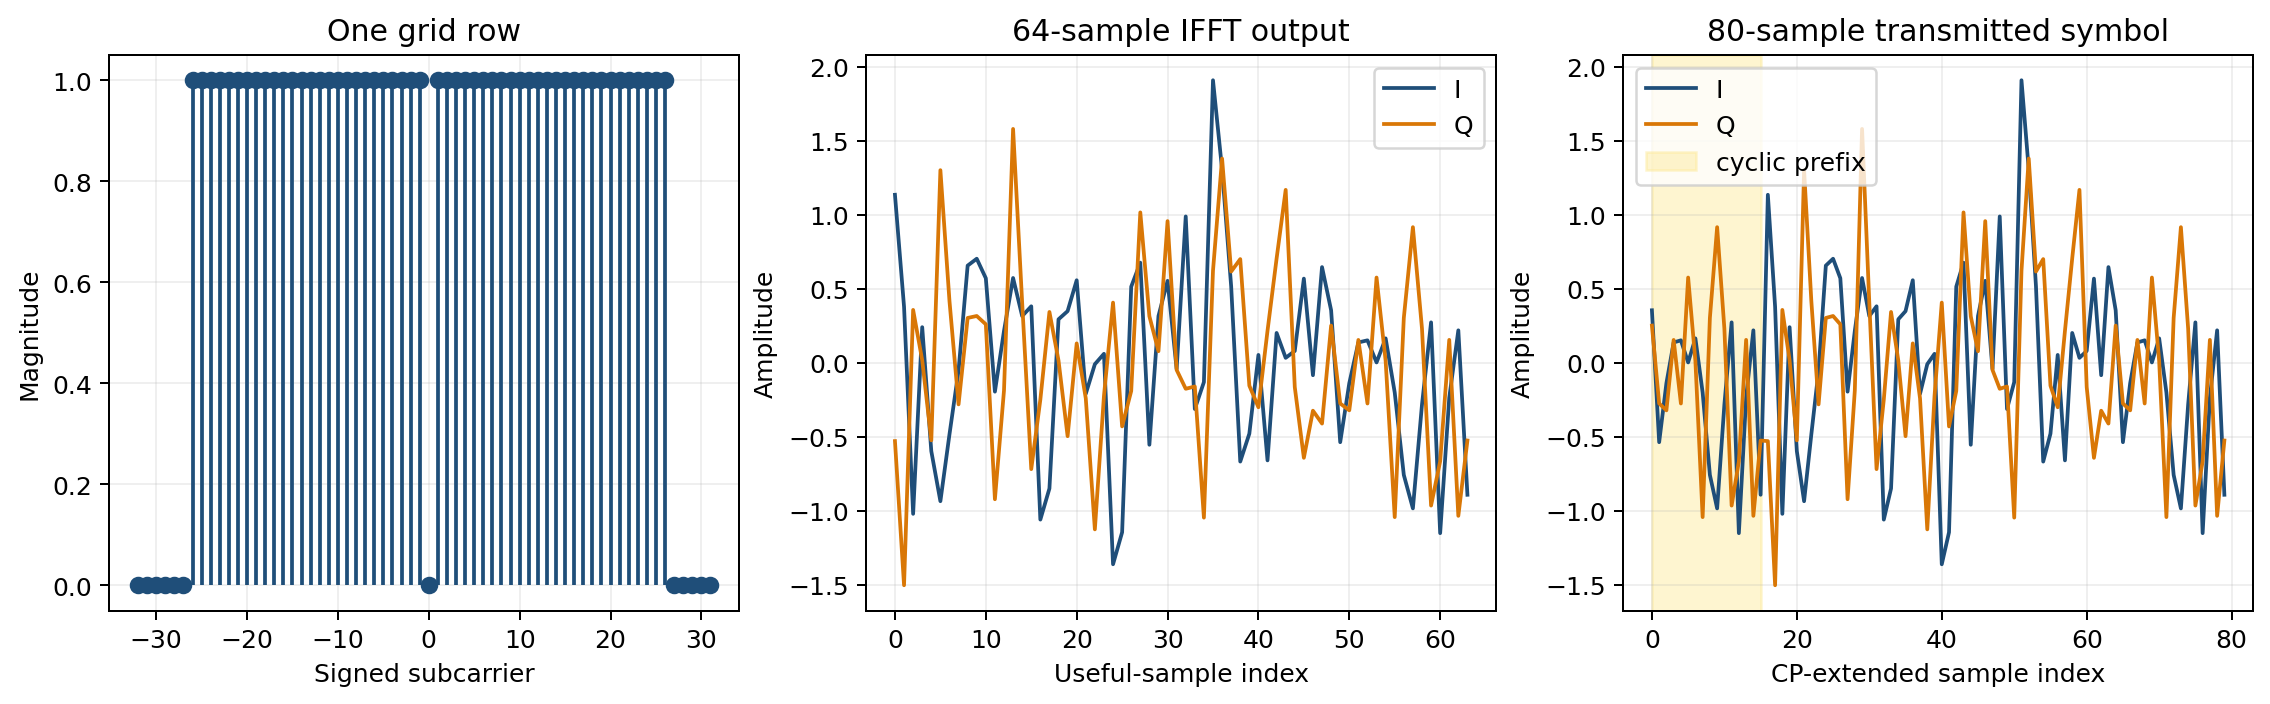

In [11]:
simulation = lab5_tools.generate_simulation(FIGURE_DIR)
for name in ('task1_frame_and_resource_grid', 'task1_ofdm_symbol'):
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))


## Report work

<span style="color:#165696"><b>Report.</b> Explain why signed negative subcarriers map to the upper NumPy indices. </span>

In the N-point DFT, frequency bins are represented modulo N, so negative frequencies wrap around to the end of the array. As a result, a signed carrier index k is mapped using $i=k \bmod N_{FFT}$, causing carriers such as −1 and −21 to appear at indices 63 and 43 when $N_{FFT}=64$. This arrangement allows NumPy FFT functions to represent both positive and negative frequency components in a single unshifted array. Using this mapping ensures the transmitter and receiver place symbols on the correct subcarriers and maintain OFDM orthogonality.

<span style="color:#165696"><b>Report.</b> Explain why the CP contains the final samples of the useful symbol. </span>

The cyclic prefix is created by copying the last $N_{CP}$ samples of the useful OFDM symbol and placing them at the beginning of the symbol. This makes the transmitted waveform appear periodic over the FFT window, allowing the receiver to model the channel's linear convolution as a circular convolution. When the channel delay spread is shorter than the CP length, intersymbol interference is confined to the CP and does not affect the useful data samples. As a result, each subcarrier experiences only a complex gain H[k], enabling simple one-tap frequency-domain equalization.

<span style="color:#165696"><b>Report.</b> Explain why clipping would destroy orthogonality even if the FFT implementation is correct. </span>

Clipping is a nonlinear operation that distorts the transmitted OFDM waveform whenever signal peaks exceed the allowed amplitude range. This distortion generates additional frequency components that were not present in the original set of orthogonal subcarriers, causing energy from one subcarrier to leak into others. The resulting intercarrier interference breaks the assumption that each subcarrier can be separated perfectly by the FFT, even if the FFT itself is implemented correctly. Therefore, clipping degrades constellation quality, increases EVM and BER, and reduces overall OFDM performance.|

# Lab 5 Task 2: AWGN, Multipath, and Cyclic Prefix

Complete the noise and one-tap equalization calculations, then run the supplied AWGN, multipath, and insufficient-CP studies.


In [1]:
from pathlib import Path
import json
import os
import sys
import numpy as np
from IPython.display import Image, display
import IPython.core.pylabtools as pylabtools

# Matplotlib 3.6 expects this compatibility table, which newer IPython omits.
if not hasattr(pylabtools, "backend2gui"):
    pylabtools.backend2gui = {}

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab5_dsp.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 5 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB5_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

import lab5_dsp as lab
import lab5_tools

print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/captures


## Noise calculation


In [2]:
ebn0_db = 10.0
qpsk_bits_per_symbol = 2

# QPSK symbols have unit energy
eb = 1.0 / qpsk_bits_per_symbol
gamma_b = 10**(ebn0_db / 10.0)
n0 = 1.0 / (2.0 * gamma_b)
real_component_variance = n0 / 2.0

print("Eb:", eb)
print("N0:", n0)
print("real-component variance:", real_component_variance)

Eb: 0.5
N0: 0.05
real-component variance: 0.025


## Channel memory and frequency-domain equalization


In [5]:
nfft = 64
ncp = 16
short_h = lab.short_channel()

# Channel memory = largest nonzero tap index
short_memory_samples = np.max(np.nonzero(np.abs(short_h) > 0)[0])
cp_is_sufficient = short_memory_samples < ncp
known_h = np.fft.fft(short_h, nfft, norm="ortho")
received_active = known_h[lab.ACTIVE_IDX] * lab.TRAINING_ACTIVE
known_h_active = known_h[lab.ACTIVE_IDX]
equalized_active = received_active / known_h_active
h_true = known_h_active
h_est = h_true + 0.01 * (1 + 1j)
channel_nmse = 10 * np.log10(
    np.mean(np.abs(h_est - h_true) ** 2)
    / np.mean(np.abs(h_true) ** 2)
)

print("channel memory (samples):", short_memory_samples)
print("CP sufficient:", cp_is_sufficient)
print("largest equalization error:",
      np.max(np.abs(equalized_active - lab.TRAINING_ACTIVE)))
print("example NMSE:", channel_nmse)

channel memory (samples): 5
CP sufficient: True
largest equalization error: 1.1340896622944255e-16
example NMSE: -18.36769079434535


In [4]:
assert np.isclose(eb, 0.5)
assert np.isclose(n0, 0.05)
assert short_memory_samples == 5
assert cp_is_sufficient
assert np.max(np.abs(equalized_active-lab.TRAINING_ACTIVE)) < 1e-12
print("Task 2 calculations passed.")


Task 2 calculations passed.


## Supplied experiments and plots


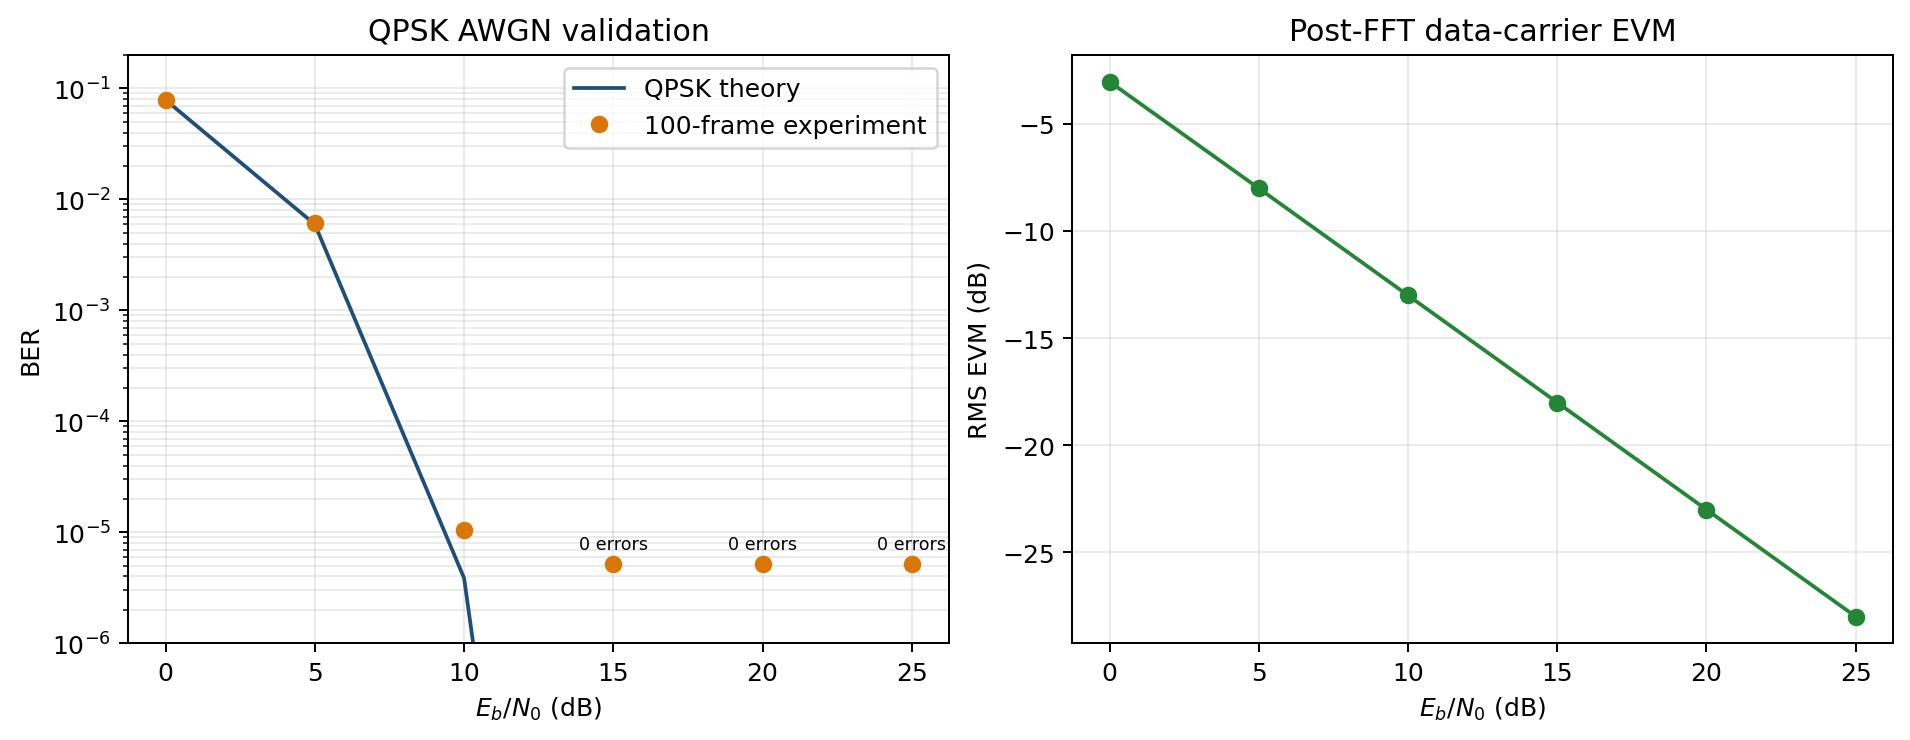

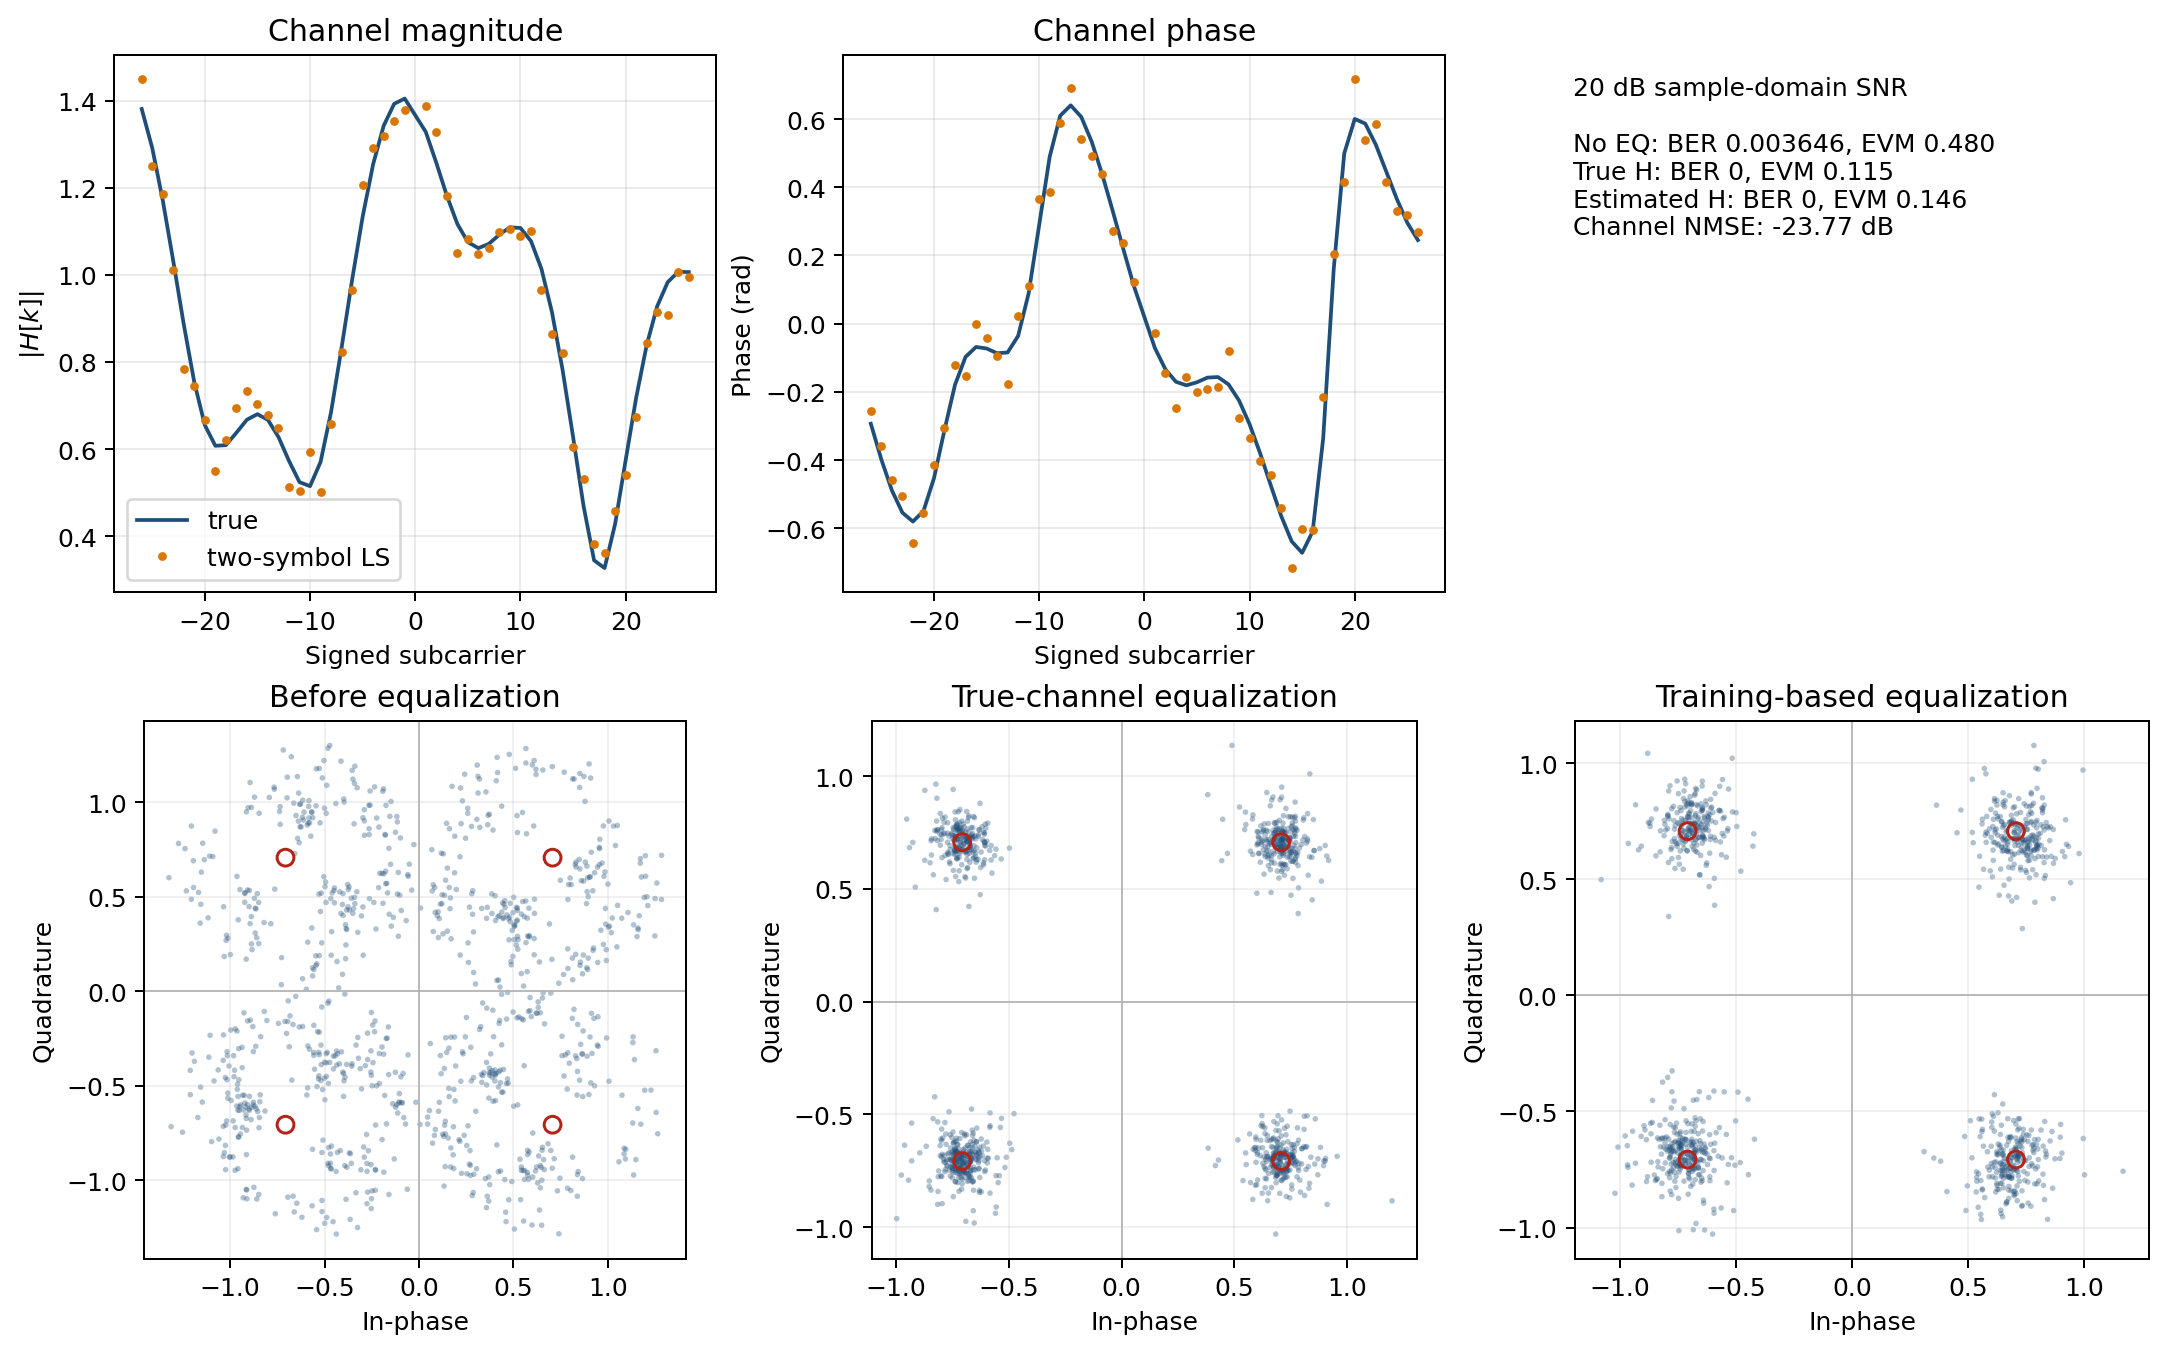

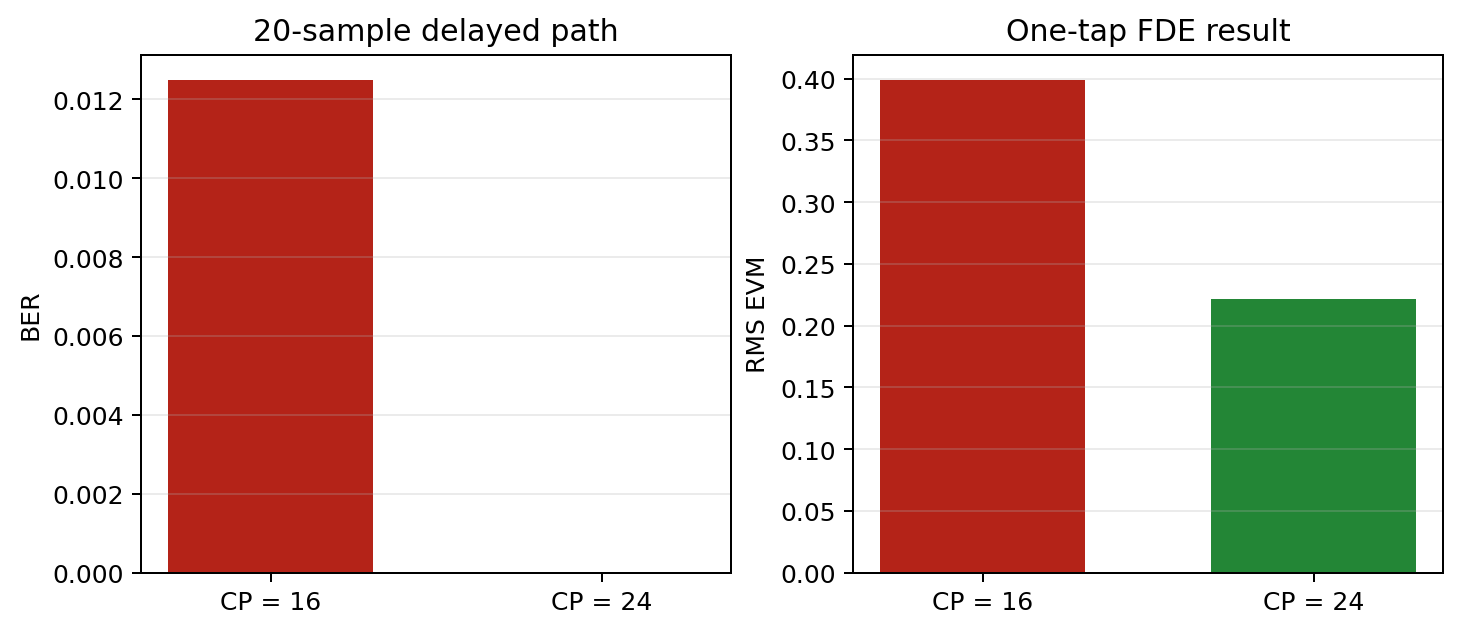

short-channel results: {
  "raw_ber": 0.0036458333333333334,
  "raw_evm_rms": 0.4800640526182244,
  "true_h_ber": 0.0,
  "true_h_evm_rms": 0.11530206374301936,
  "estimated_h_ber": 0.0,
  "estimated_h_evm_rms": 0.145565455855104,
  "channel_nmse": 0.004195551352448124
}
CP comparison: [
  {
    "ncp": 16,
    "ber": 0.0125,
    "evm_rms": 0.39928752581279975
  },
  {
    "ncp": 24,
    "ber": 0.0,
    "evm_rms": 0.22193655439151982
  }
]


In [6]:
simulation = lab5_tools.generate_simulation(FIGURE_DIR)
for name in ('task2_awgn_ber_evm', 'task2_multipath_equalization', 'task2_cp_comparison'):
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))
›
print("short-channel results:", json.dumps(simulation["short_channel"], indent=2))
print("CP comparison:", json.dumps(simulation["cp_comparison"], indent=2))


## Report work

<span style="color:#165696"><b>Report.</b> Compare simulated QPSK BER with theory and state the finite-trial resolution. </span>

The simulated QPSK BER closely follows the theoretical AWGN BER curve at low and moderate $E_b/N_0$ values. At 15, 20, and 25 dB, no bit errors were observed over the 100-frame experiment, so those points are plotted at the finite-trial resolution of $1/192{,}000 \approx 5.2\times10^{-6}$ on the log-scale BER plot. This resolution corresponds to the smallest nonzero BER that could be measured, since a single bit error among 192,000 transmitted bits would produce a BER of $5.2\times10^{-6}$. Therefore, the zero-error measurements remain consistent with the theoretical BER, which is much smaller than the experiment's measurement resolution at high $E_b/N_0$.

<span style="color:#165696"><b>Report.</b> Compare no equalizer, true-channel ZF, and training-estimated ZF. </span>

Without equalization, the frequency-selective channel causes the received constellation to be distorted and spread around the ideal QPSK symbol locations, resulting in a BER of 0.003646 and an EVM of 0.480. The unequal subcarrier gains and phase rotations introduce significant symbol errors because the channel response is not compensated.

Using true-channel ZF equalization, the exact channel response $H[k]$ is applied to remove the channel distortion on each subcarrier. This produces tightly clustered constellation points near the ideal QPSK locations and achieves a BER of 0 with an EVM of 0.115, representing the best possible equalization performance.

Using training-estimated ZF equalization, the channel is estimated from the two training symbols and then used for equalization. The estimated channel closely matches the true channel, with a channel NMSE of $-23.77$ dB, and the constellation remains well clustered. Although the estimation error slightly increases the EVM to 0.146, the BER remains 0, demonstrating that the two-symbol LS channel estimate is sufficiently accurate for reliable packet recovery.

<span style="color:#165696"><b>Report.</b> Explain the channel NMSE result. </span>

The channel estimate achieved an NMSE of $-23.77$ dB, meaning the estimated channel $\hat{H}[k]$ is very close to the true channel $H[k]$. This corresponds to an estimation error power of only about $10^{-23.77/10}\approx0.0042$, or $0.42\%$ of the channel power. As a result, the training-estimated ZF equalizer performs nearly as well as true-channel ZF, achieving the same BER of 0 with only a small increase in EVM from 0.115 to 0.146.

<span style="color:#165696"><b>Report.</b> Explain why CP 16 fails for the delay-20 channel while CP 24 succeeds. </span>

The delayed channel contains a path at a delay of 20 samples. With $N_{CP}=16$, the delayed path extends beyond the cyclic prefix, causing inter-symbol interference (ISI) and inter-carrier interference (ICI), which violates the circular-convolution assumption required for one-tap frequency-domain equalization. As a result, the BER increases to 0.0125 and the EVM increases to 0.399 because a one-tap equalizer cannot correct the resulting distortion.

With $N_{CP}=24$, the entire channel delay spread fits within the cyclic prefix, preserving the circular-convolution model $Y[k]=H[k]X[k]$. This allows the one-tap frequency-domain equalizer to properly compensate for the channel on each subcarrier, resulting in a BER of 0 and a lower EVM of 0.222.

<span style="color:#165696"><b>Report.</b> Explain why a one-tap equalizer cannot remove interference created before the FFT. </span>

A one-tap equalizer assumes that each subcarrier experiences only a complex gain, so the received signal can be modeled as $Y[k]=H[k]X[k]$. When the channel delay spread exceeds the cyclic prefix, interference is created in the time domain before the FFT, causing both inter-symbol interference (ISI) and inter-carrier interference (ICI). This violates the OFDM orthogonality assumption and means that energy from one symbol and one subcarrier leaks into others. Because a one-tap equalizer can only multiply each subcarrier by a scalar, it cannot undo the mixing between symbols and subcarriers caused by pre-FFT interference.

# Lab 5 Task 3: Automatic OFDM Receiver

Complete the CFO, channel-estimation, equalizer-floor, and pilot-phase equations. Then exercise the frozen receiver on a deterministic impaired capture and a 100-trial Monte Carlo study


In [2]:
from pathlib import Path
import json
import os
import sys
import numpy as np
from IPython.display import Image, display
import IPython.core.pylabtools as pylabtools

# Matplotlib 3.6 expects this compatibility table, which newer IPython omits.
if not hasattr(pylabtools, "backend2gui"):
    pylabtools.backend2gui = {}

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab5_dsp.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 5 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB5_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

import lab5_dsp as lab
import lab5_tools

print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/captures


## Receiver equations


<span style="color:#165696"><b>Report.</b> Derive the CFO estimator and its ambiguity interval. </span>

The CFO estimator uses the phase rotation between repeated sections of the short preamble. The correlation $P[d]=\sum r^*[d+n]\,r[d+n+L]$ contains a phase term $e^{j2\pi\Delta fL/f_s}$ due to the carrier frequency offset. Taking the angle of $P[d]$ gives $\hat{\Delta f}=\frac{f_s}{2\pi L}\angle P[\hat d]$. For the example $f_s=1\ \text{MHz}$, $L=16$, and $\angle P=0.4$ rad, $\hat{\Delta f}=\frac{1{,}000{,}000}{2\pi(16)}(0.4)\approx 3.98\ \text{kHz}$. Because the measured phase is limited to $[-\pi,\pi)$, the ambiguity interval is $\Delta f\in\left[-\frac{f_s}{2L},\frac{f_s}{2L}\right)$ which gives $\Delta f\in[-31.25,\ 31.25)\ \text{kHz}$ for $f_s=1$ MHz and $L=16$.

In [3]:
sample_rate_sps = 1_000_000
repeat_length = 16
p_value = np.exp(1j*0.4)

# CFO ambiguity range: ±fs/(2L)
cfo_ambiguity_hz = sample_rate_sps / (2 * repeat_length)

# CFO estimate: fs/(2πL) * angle(P)
cfo_estimate_hz = sample_rate_sps / (2 * np.pi * repeat_length) * np.angle(p_value)

known_training = np.ones((2, 52), dtype=complex)
true_channel = np.linspace(0.4, 1.2, 52) * np.exp(1j * np.linspace(-0.5, 0.7, 52))
received_training = known_training * true_channel

# Two-symbol LS estimate
channel_estimate = np.mean(received_training / known_training, axis=0)

# Relative ZF floor
zf_floor = 0.05 * np.median(np.abs(channel_estimate))

known_pilots = np.array([1, 1, 1, -1], dtype=complex)
equalized_pilots = known_pilots * np.exp(1j * 0.2)

# Common phase error estimate
cpe_rad = np.angle(np.sum(np.conj(known_pilots) * equalized_pilots))

print("CFO ambiguity limit (Hz):", cfo_ambiguity_hz)
print("example CFO estimate (Hz):", cfo_estimate_hz)
print("channel-estimation maximum error:", np.max(np.abs(channel_estimate - true_channel)))
print("relative ZF floor:", zf_floor)
print("pilot CPE (rad):", cpe_rad)

CFO ambiguity limit (Hz): 31250.0
example CFO estimate (Hz): 3978.8735772973837
channel-estimation maximum error: 0.0
relative ZF floor: 0.04000000000000001
pilot CPE (rad): 0.2


In [4]:
assert cfo_ambiguity_hz == 31_250
assert np.max(np.abs(channel_estimate-true_channel)) < 1e-12
assert np.isclose(cpe_rad, 0.2)
print("Receiver-equation checks passed.")


Receiver-equation checks passed.


## Synthetic acquisition and Monte Carlo


<span style="color:#165696"><b>Report.</b> Report detection, timing, CFO RMSE, BER, PER, EVM, and every failure mode from the 100 trials. </span>

No acquisition failures or timing failures were observed over the 100 trials, resulting in a 100% detection rate and 100% timing-within-one-sample rate. The only observed failures were two CRC packet failures, producing a PER of 2.0%, while the overall BER remained low at $1.04\times10^{-5}$. The remaining metrics were output below.

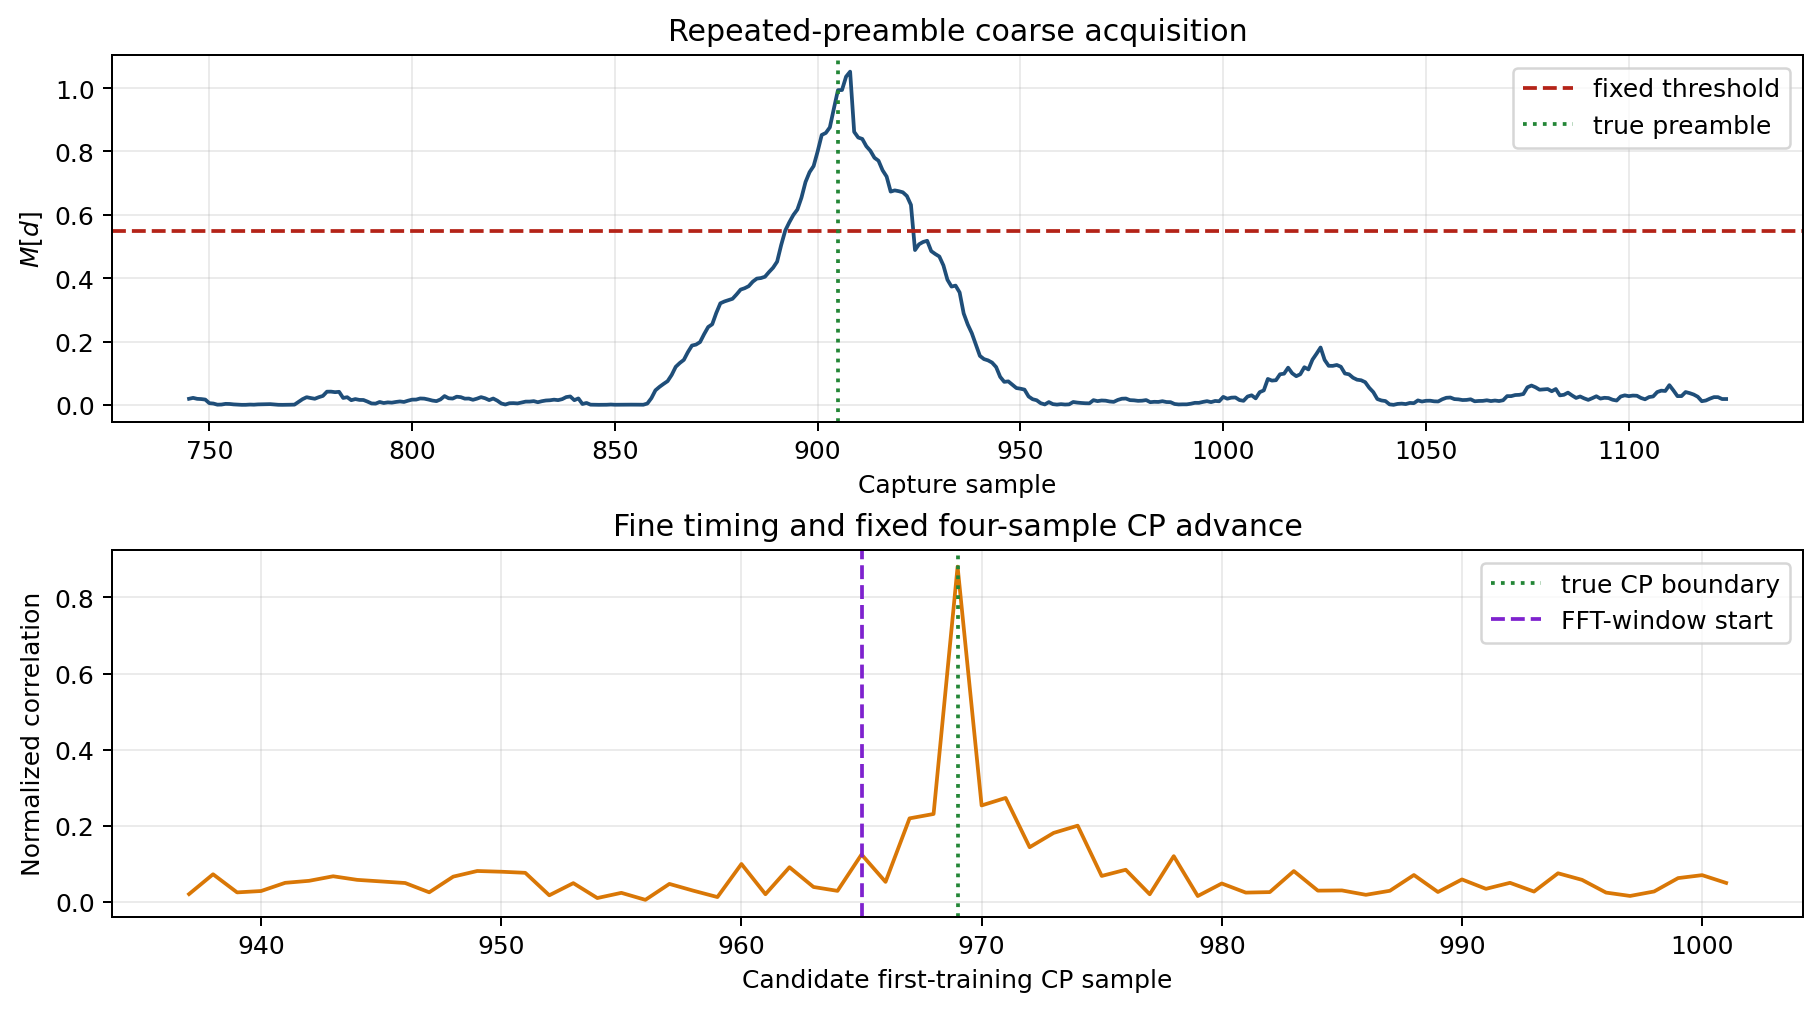

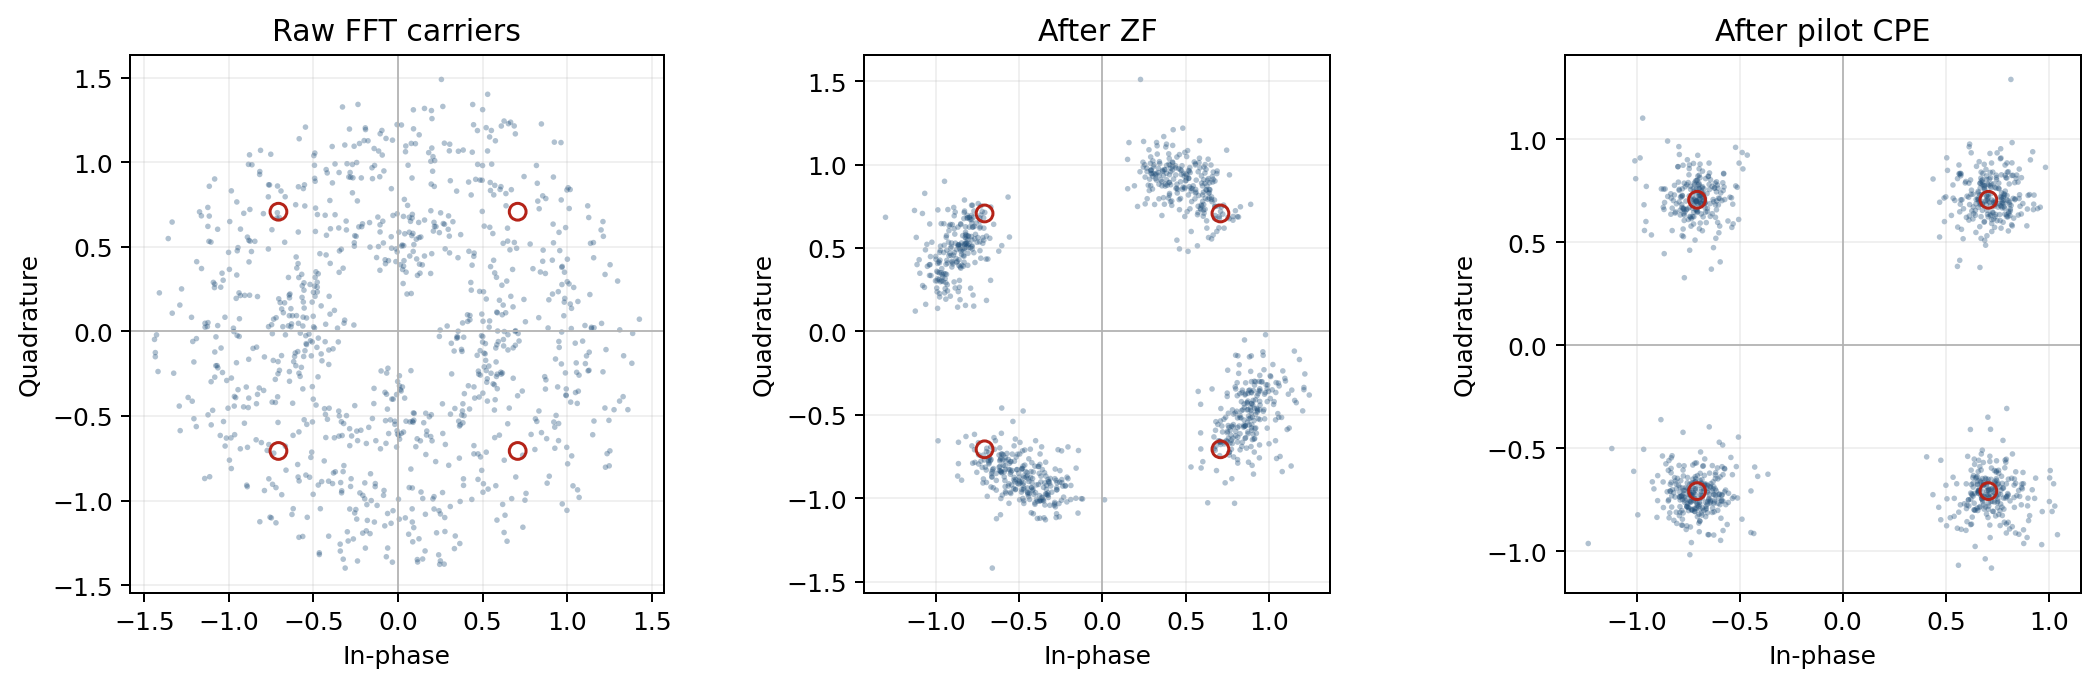

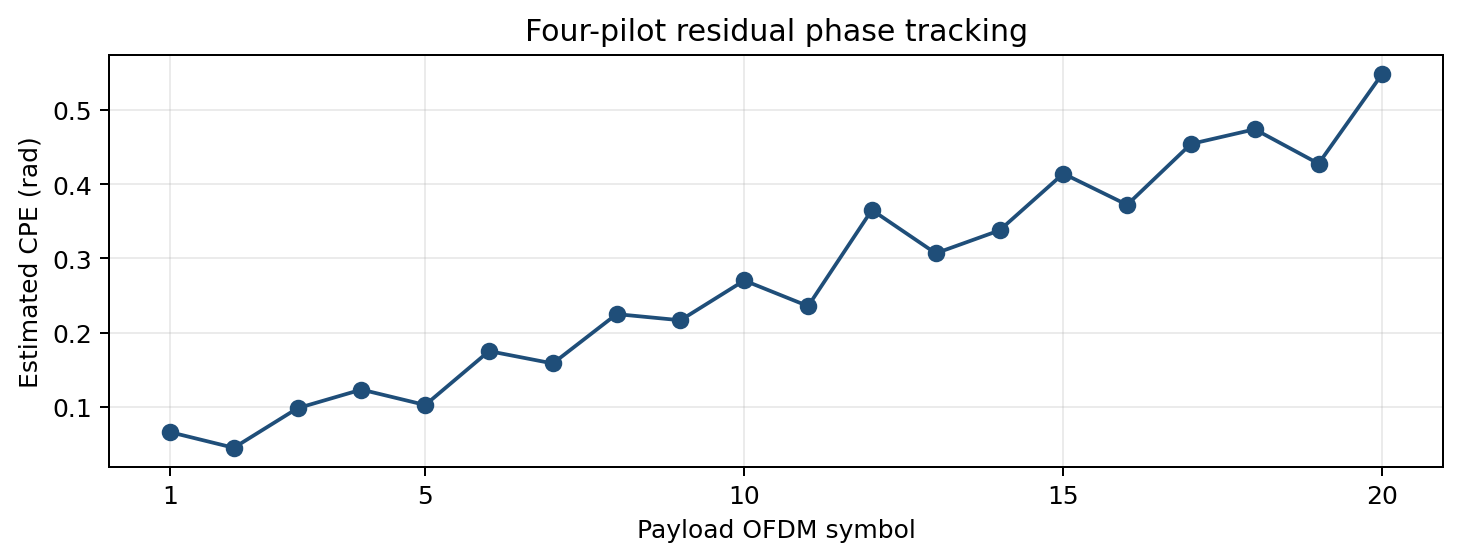

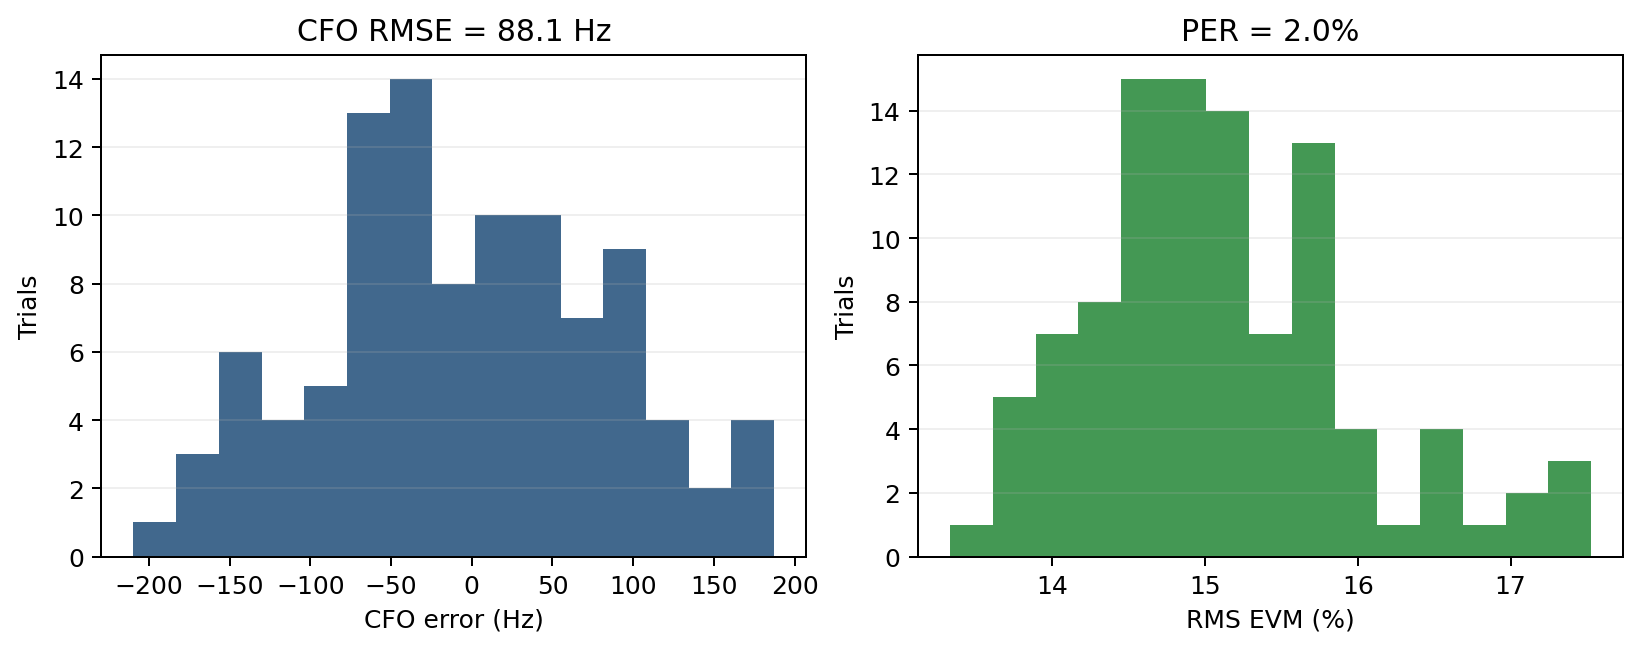

fixed case: {
  "true_cfo_hz": 7500.0,
  "estimated_cfo_hz": 7448.986521864943,
  "cfo_error_hz": -51.013478135057085,
  "timing_error_samples": 0,
  "ber": 0.0,
  "evm_rms": 0.15006152062060268,
  "crc_ok": true
}
Monte Carlo: {
  "trials": 100,
  "detected": 100,
  "detection_rate": 1.0,
  "timing_within_one_rate": 1.0,
  "cfo_rmse_hz": 88.14839886452513,
  "ber": 1.0416666666666666e-05,
  "packet_error_rate": 0.020000000000000018,
  "mean_evm_rms": 0.1511880996510483
}


In [5]:
simulation = lab5_tools.generate_simulation(FIGURE_DIR)
for name in ('task3_synthetic_acquisition', 'task3_synthetic_constellations', 'task3_pilot_cpe', 'task3_monte_carlo'):
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))

print("fixed case:", json.dumps(simulation["synthetic_acquisition"], indent=2))
print("Monte Carlo:", json.dumps(simulation["monte_carlo"], indent=2))


## Report work

<span style="color:#165696"><b>Report.</b> Explain the coarse repeated-field metric and the fine training correlation. </span>

The coarse repeated-field metric exploits the 16-sample repetition in the short preamble. It computes the normalized correlation $M[d]=\frac{|P[d]|^2}{R[d]^2+\epsilon}$, which produces a strong peak when two adjacent repeated sections align, providing a coarse estimate of the frame start and the CFO phase rotation. In the measured result, the acquisition peak exceeds the 0.55 threshold and occurs near the true preamble location, indicating successful frame detection.

After CFO correction, fine timing is performed by cross-correlating with the known two-symbol training sequence within $\pm 32$ samples of the coarse estimate. Because the training symbols are known exactly, the correlation produces a sharp peak at the correct CP boundary, allowing accurate FFT-window placement before channel estimation and equalization. The FFT window is then intentionally advanced by four samples into the cyclic prefix, leaving 12 CP samples for channel settling rather than representing a timing error.

<span style="color:#165696"><b>Report.</b> Explain the four-sample FFT-window advance into the cyclic prefix. </span>

The fine timing estimate identifies the first-training CP boundary, but the FFT window is intentionally started 4 samples earlier, inside the cyclic prefix. Since the CP length is 16 samples, this leaves 12 CP samples before the useful symbol begins, providing margin for channel transients and timing uncertainty. Because the cyclic prefix is a copy of the end of the symbol, starting the FFT window anywhere within the CP preserves the circular-convolution model and does not introduce distortion. Therefore, the 4-sample advance is a deliberate design choice rather than a timing error.

<span style="color:#165696"><b>Report.</b> Distinguish full-band training from the four payload pilots. </span>

The full-band training symbols are used once at the start of the frame to estimate $\hat H[k]$ on all active subcarriers for equalization. This is visible when comparing the "Raw FFT carriers" and "After ZF" constellations, where the distorted ring-shaped constellation is transformed into four distinct QPSK clusters.

The four payload pilots are then used to estimate and correct the residual common phase error (CPE) in each OFDM symbol. Comparing the "After ZF" and "After pilot CPE" constellations shows that the pilots remove the remaining constellation rotation and tighten the clusters around the ideal QPSK locations. The CPE plot shows that the required phase correction varies across the packet, demonstrating continuous pilot-based tracking of residual phase drift.

# Lab 5 Task 4: Real N310 OFDM Link

Verify file sizes and finite-transmission accounting, acquire uncropped files with the supplied GNU Radio graphs, and run the same receiver used in Task 3 on data captured on the N310


In [1]:
from pathlib import Path
import json
import os
import sys
import numpy as np
from IPython.display import Image, display
import IPython.core.pylabtools as pylabtools

# Matplotlib 3.6 expects this compatibility table, which newer IPython omits.
if not hasattr(pylabtools, "backend2gui"):
    pylabtools.backend2gui = {}

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab5_dsp.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 5 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB5_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

import lab5_dsp as lab
import lab5_tools

print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/captures


## Finite-file and capture calculations


In [2]:
sample_rate_sps = 1_000_000
period_samples = 8192
repeat_count = 13
warmup_periods = 1
acquisition_lead_samples = 2_000_000
capture_seconds = 15.0

# Exact counts
payload_burst_samples = repeat_count * period_samples
transmit_samples = acquisition_lead_samples + payload_burst_samples
transmit_bytes = transmit_samples * 8          # complex64

capture_samples = int(capture_seconds * sample_rate_sps)
capture_bytes = capture_samples * 8            # complex64

expected_frames = repeat_count - warmup_periods

print("OFDM burst samples:", payload_burst_samples)
print("guarded TX samples and bytes:", transmit_samples, transmit_bytes)
print("RX samples and bytes:", capture_samples, capture_bytes)
print("graded frames:", expected_frames)

OFDM burst samples: 106496
guarded TX samples and bytes: 2106496 16851968
RX samples and bytes: 15000000 120000000
graded frames: 12


In [3]:
assert payload_burst_samples == 106_496
assert transmit_samples == 2_106_496
assert transmit_bytes == 16_851_968
assert capture_samples == 15_000_000
assert capture_bytes == 120_000_000
assert expected_frames == 12
print("Hardware accounting passed.")


Hardware accounting passed.


## Build the finite transmitter file and metadata


<span style="color:#165696"><b>Report.</b> Confirm the TX file is 16,851,968 bytes. </span>

In [7]:
!ls -la $WAVEFORM_DIR/task4_ofdm_13period_c64.dat

-rw-r--r--  1 marcpham  staff  16851968 Oct 27 20:29 /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/waveforms/task4_ofdm_13period_c64.dat


In [4]:
tx_gains_db = (40, 45, 50)
rx_gain_db = 60

prepared = lab5_tools.prepare_hardware_experiment(
    WAVEFORM_DIR,
    CAPTURE_DIR,
    tx_gains_db=tx_gains_db,
    rx_gain_db=rx_gain_db,
)
print(json.dumps(prepared, indent=2))
assert prepared["waveform_bytes"] == 16_851_968


{
  "waveform_path": "/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/waveforms/task4_ofdm_13period_c64.dat",
  "waveform_bytes": 16851968,
  "summary_path": "/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/captures/lab5_measurement_summary.json",
  "summary": {
    "waveform": {
      "tx_gains_db": [
        40,
        45,
        50
      ],
      "measurement_periods": 12,
      "warmup_periods": 1,
      "repeat_count": 13,
      "capture_duration_s": 15.0,
      "capture_samples": 15000000,
      "sample_rate_sps": 1000000.0,
      "center_frequency_hz": 2450000000.0,
      "rx_gain_db": 60.0,
      "period_samples": 8192,
      "active_frame_samples": 2080,
      "acquisition_lead_samples": 2000000,
      "finite_tx_samples": 2106496,
      "digital_peak": 0.10000000149011612,
      "period_sha256": "a1e8eceb01c8c6d9eeb0d374cd2cbb2668a17f9f90a3f828317c2bfe7094eaba",
      "file_sha256": "f957d2fa3fb606170cf1daebe12a2

## GNU Radio acquisition

Open `flowgraphs/lab5_finite_ofdm_receiver.grc` on the RX desktop and `flowgraphs/lab5_finite_ofdm_transmitter.grc` on the TX desktop. Verify the assigned device argument, subdevice, antenna, 1 MS/s rate, 2.45 GHz center, gain, and file paths.

1. With TX stopped, set the RX output to `work/captures/lab5_noise_c64.dat`, set the capture to 0.25 seconds, and run RX once.
2. Restore the RX capture to 15 seconds.
3. For each assigned TX gain, set the RX output to `work/captures/lab5_ofdm_tx<gain>_c64.dat`.
4. Start RX first, then TX. Do not crop the raw file.
5. Confirm that the noise file is 2,000,000 bytes and every gain file is 120,000,000 bytes.


<span style="color:#165696"><b>Report.</b> Include the TX and RX flowgraphs and verify every hardware field. </span>

Transmitter Flowgraph

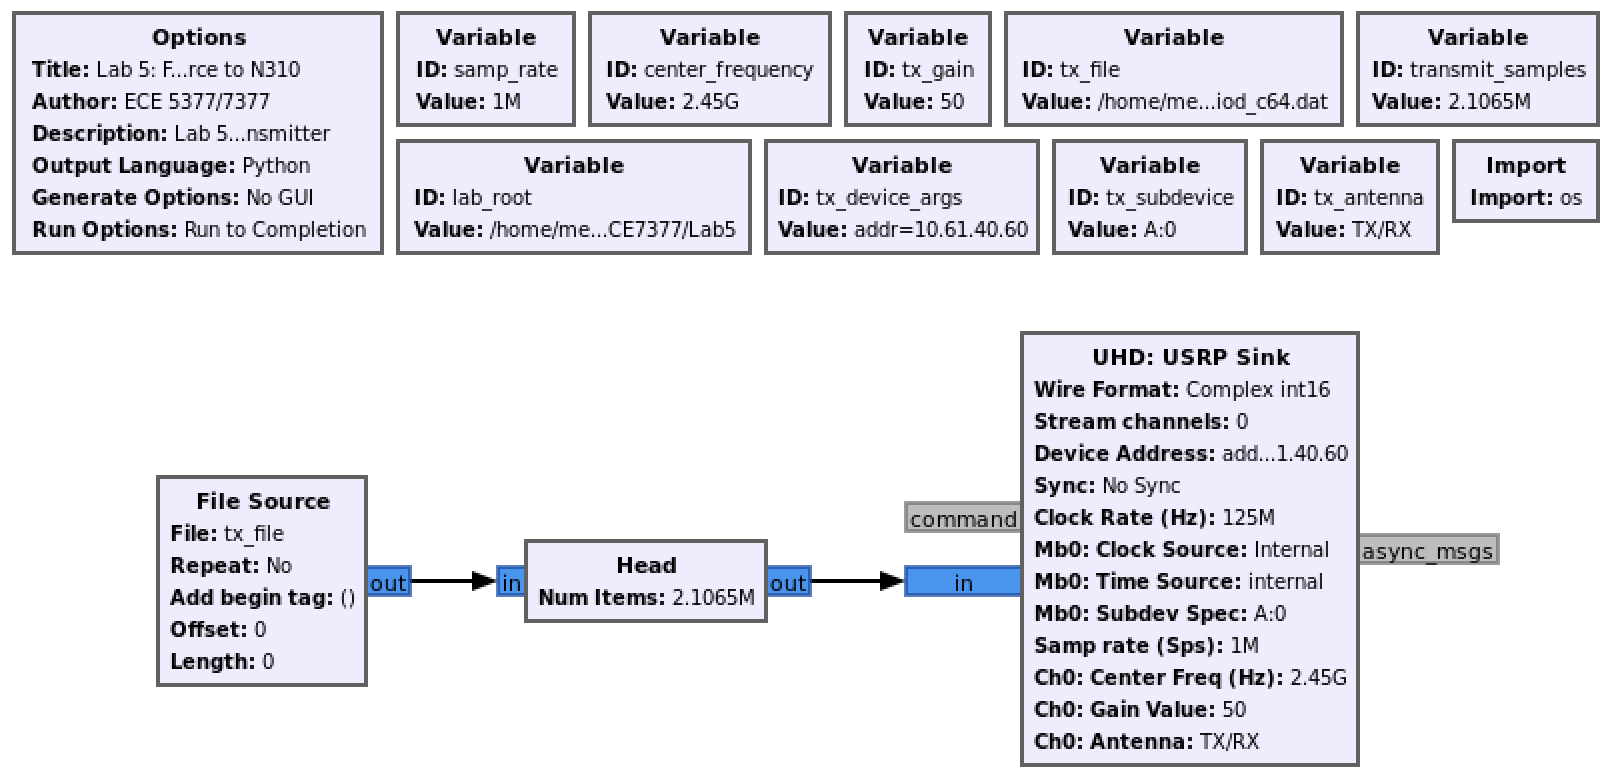

Receiver Flowgraph

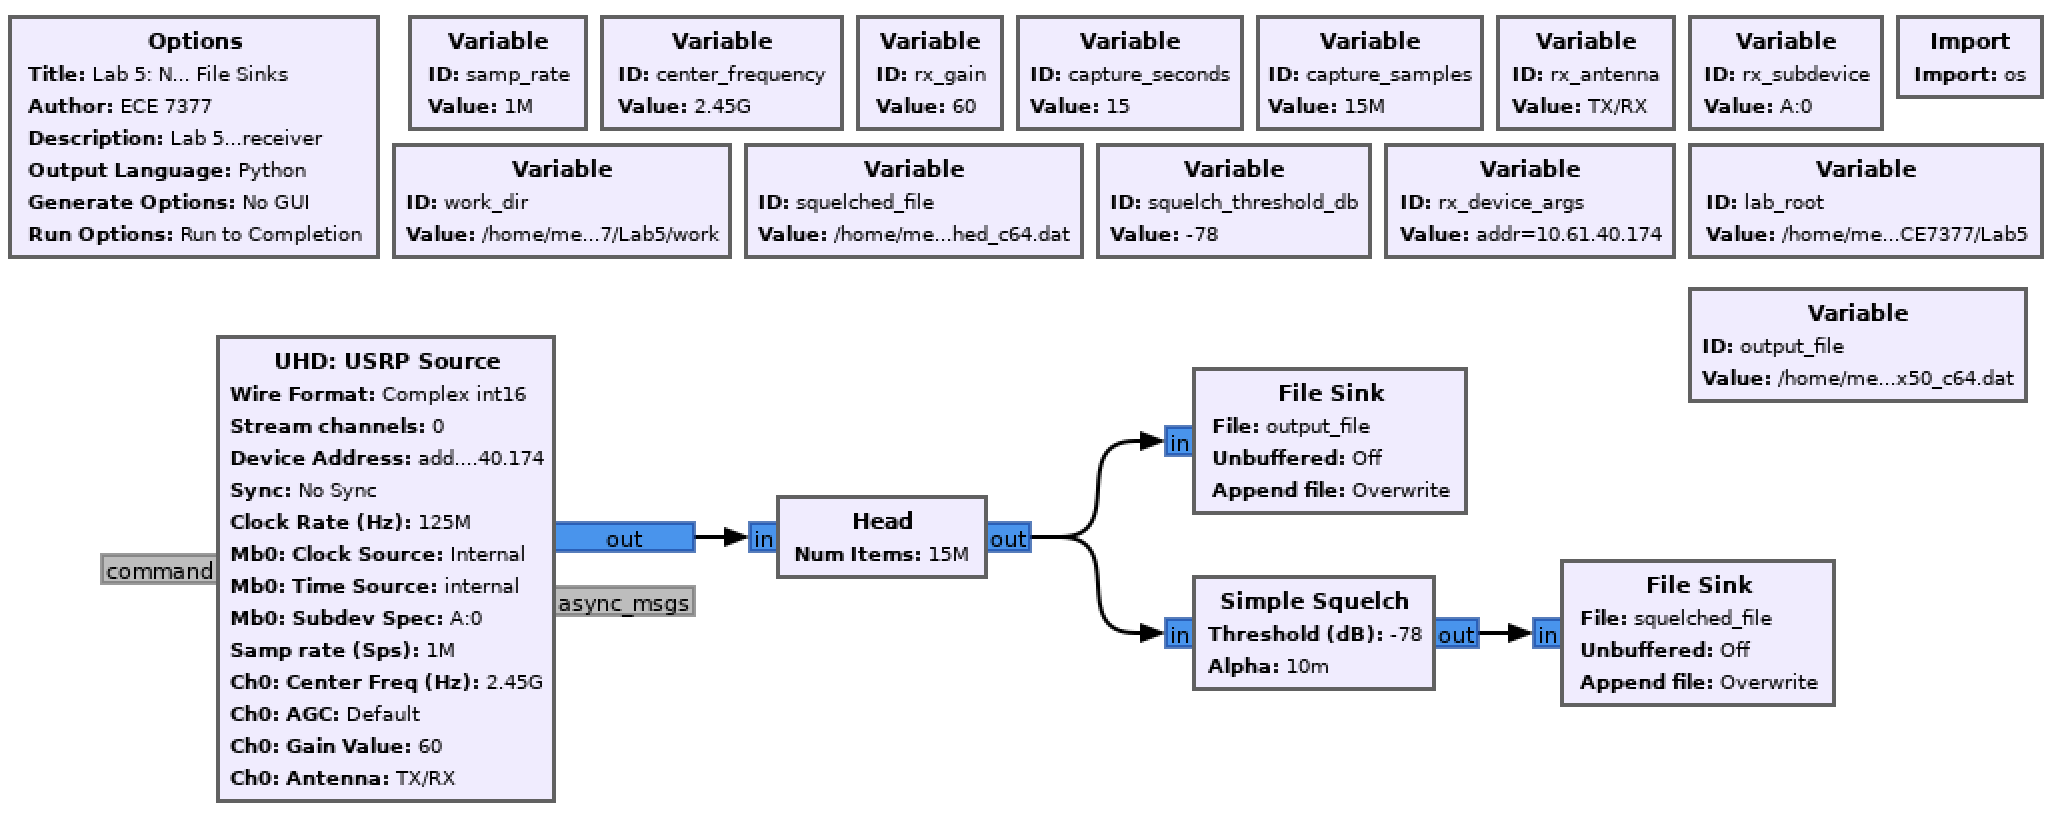

<span style="color:#165696"><b>Report.</b> Save the TX and RX console logs. </span>

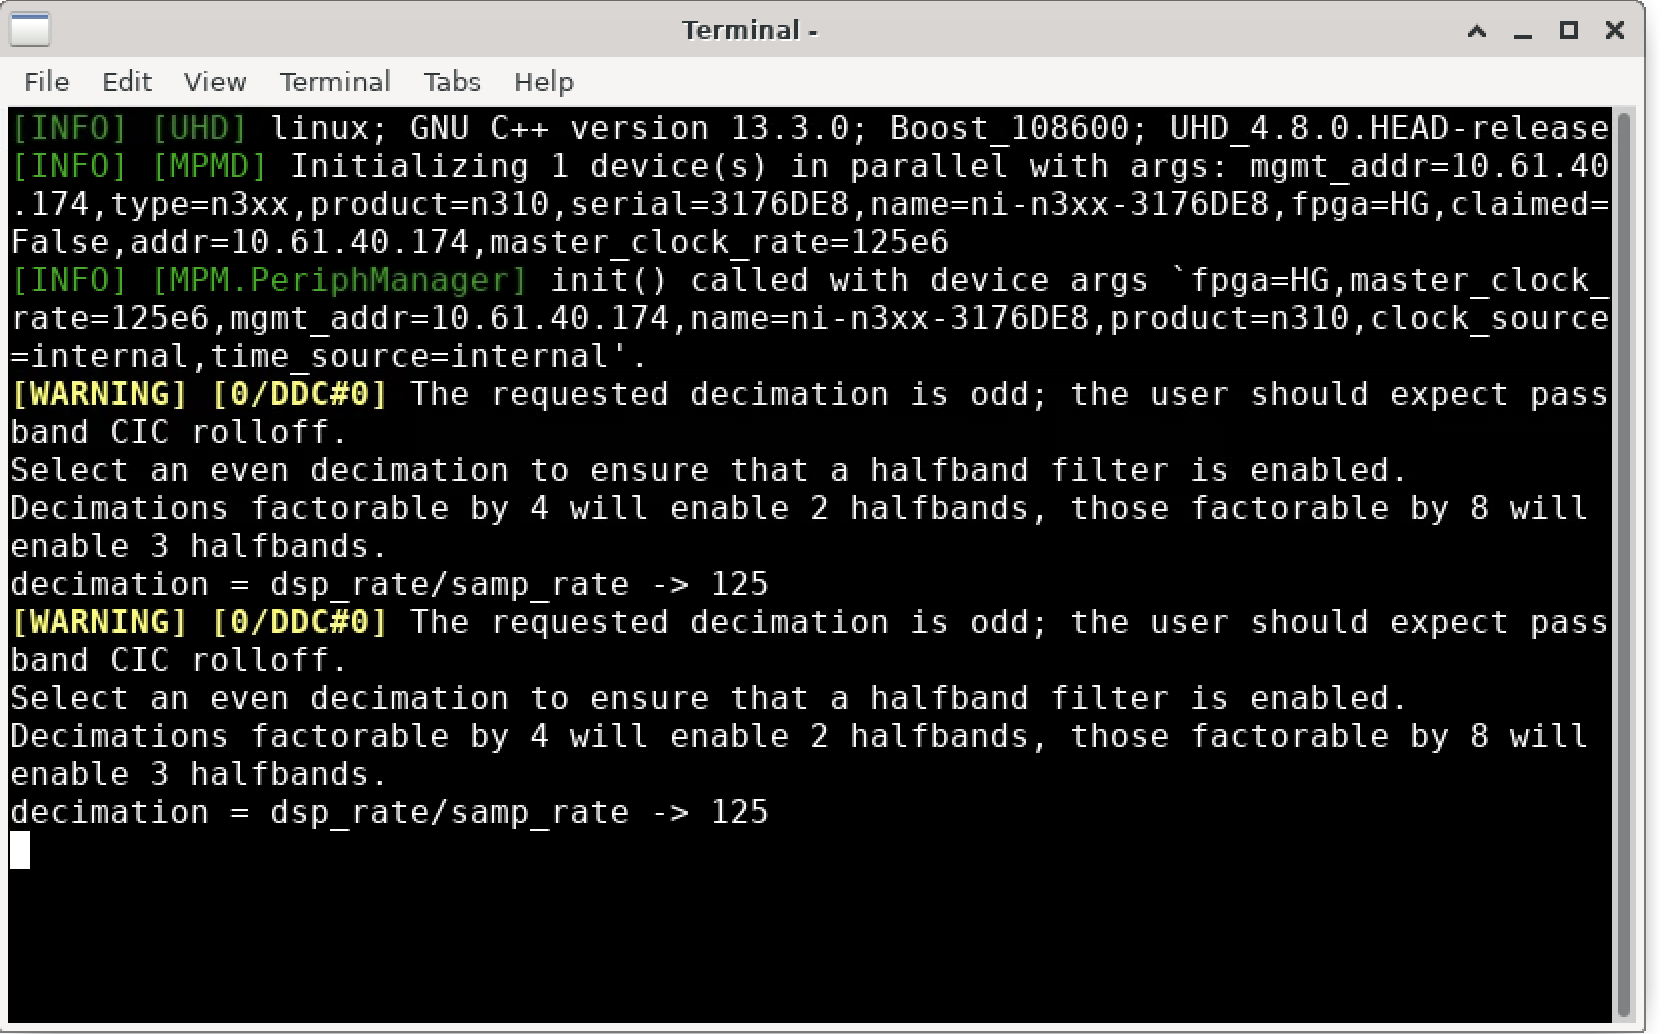

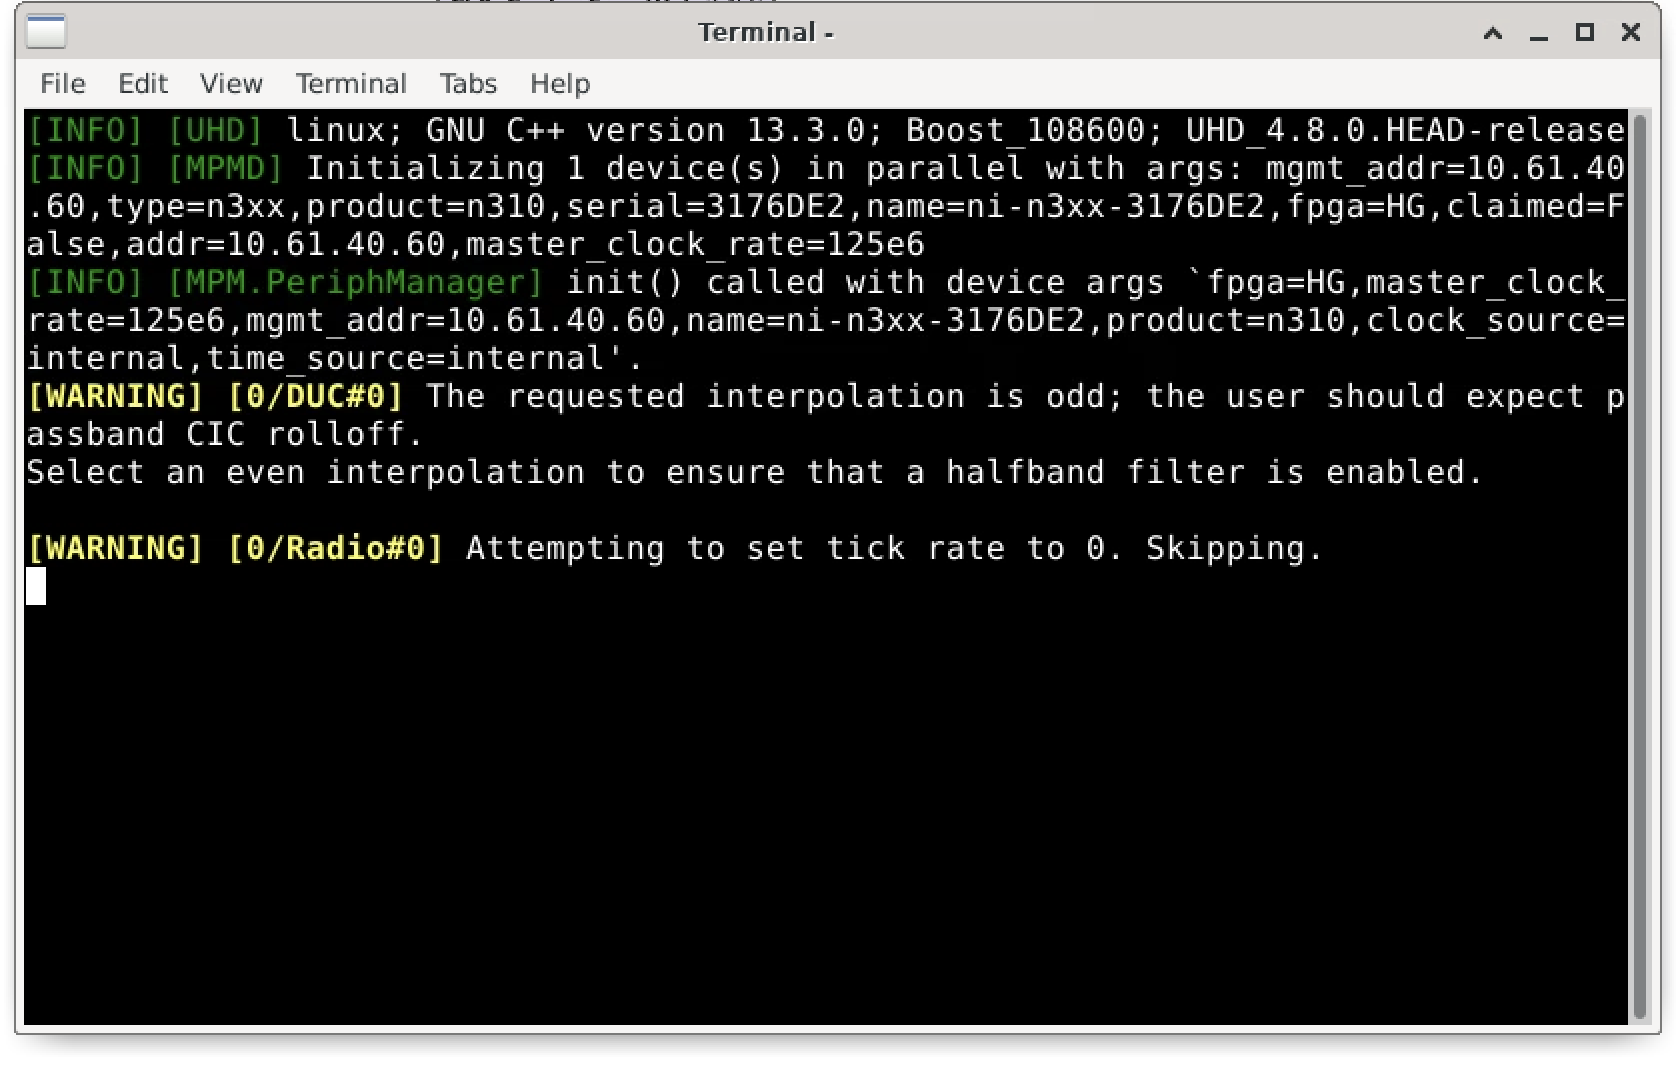

## Analyze the uncropped hardware data


<span style="color:#165696"><b>Report.</b> Confirm the noise file is 2,000,000 bytes. Confirm that the three gain files are 120,000,000 bytes each. </span>

In [12]:
!ls -la $CAPTURE_DIR 

total 941424
drwxr-xr-x  9 marcpham  staff        288 Oct 27 21:22 .
drwxr-xr-x  5 marcpham  staff        160 Oct 26 19:37 ..
drwxr-xr-x  2 marcpham  staff         64 Oct 27 21:22 .ipynb_checkpoints
-rw-r--r--  1 marcpham  staff  120000000 Oct 27 21:22 lab5_inspection_squelched_c64.dat
-rw-r--r--  1 marcpham  staff        678 Oct 27 20:29 lab5_measurement_summary.json
-rw-r--r--  1 marcpham  staff    2000000 Oct 27 21:22 lab5_noise_c64.dat
-rw-r--r--  1 marcpham  staff  120000000 Oct 27 21:22 lab5_ofdm_tx40_c64.dat
-rw-r--r--  1 marcpham  staff  120000000 Oct 27 21:22 lab5_ofdm_tx45_c64.dat
-rw-r--r--  1 marcpham  staff  120000000 Oct 27 21:22 lab5_ofdm_tx50_c64.dat


<span style="color:#165696"><b>Report.</b> Report detected frames, analyzed frames, detection rate, BER, PER, EVM, CFO mean and standard deviation, channel power, and estimated SNR for each gain. </span>

In [8]:
summary_path = CAPTURE_DIR / "lab5_measurement_summary.json"
required = [summary_path, CAPTURE_DIR / "lab5_noise_c64.dat"]
if not all(path.exists() for path in required):
    raise FileNotFoundError("Capture the noise and three gain files before running this cell.")

hardware = lab5_tools.analyze_hardware(CAPTURE_DIR, FIGURE_DIR)
for gain_name, row in hardware["gain_results"].items():
    print(gain_name, json.dumps(row["aggregate"], indent=2))


tx40 {
  "detected_frames_including_warmup": 13,
  "analyzed_frames": 12,
  "detection_rate": 1.0,
  "bit_errors": 0,
  "ber": 0.0,
  "packet_error_rate": 0.0,
  "evm_rms": 0.038839613670685225,
  "cfo_mean_hz": 10.922422722624006,
  "cfo_std_hz": 59.23768095550998,
  "fine_correlation_mean": 0.8526015275671299,
  "channel_power": 1.685848199387624e-05,
  "snr_estimate_db": 35.20337873041737,
  "capture_peak": 0.009464920498430729,
  "clipped_sample_count": 0
}
tx45 {
  "detected_frames_including_warmup": 13,
  "analyzed_frames": 12,
  "detection_rate": 1.0,
  "bit_errors": 0,
  "ber": 0.0,
  "packet_error_rate": 0.0,
  "evm_rms": 0.026604217273013833,
  "cfo_mean_hz": 43.320241916776716,
  "cfo_std_hz": 39.03098258387305,
  "fine_correlation_mean": 0.8730506530519149,
  "channel_power": 5.4011536419302364e-05,
  "snr_estimate_db": 40.260059380849796,
  "capture_peak": 0.018056463450193405,
  "clipped_sample_count": 0
}
tx50 {
  "detected_frames_including_warmup": 13,
  "analyzed_frame

<span style="color:#165696"><b>Report.</b> Show one frame from coarse acquisition through CRC. </span>

Example frame processing showing coarse acquisition using the repeated-preamble metric, fine timing synchronization using cyclic-prefix correlation, FFT demodulation, channel estimation and zero-forcing equalization, pilot-based common phase error correction, and successful packet recovery with CRC pass.

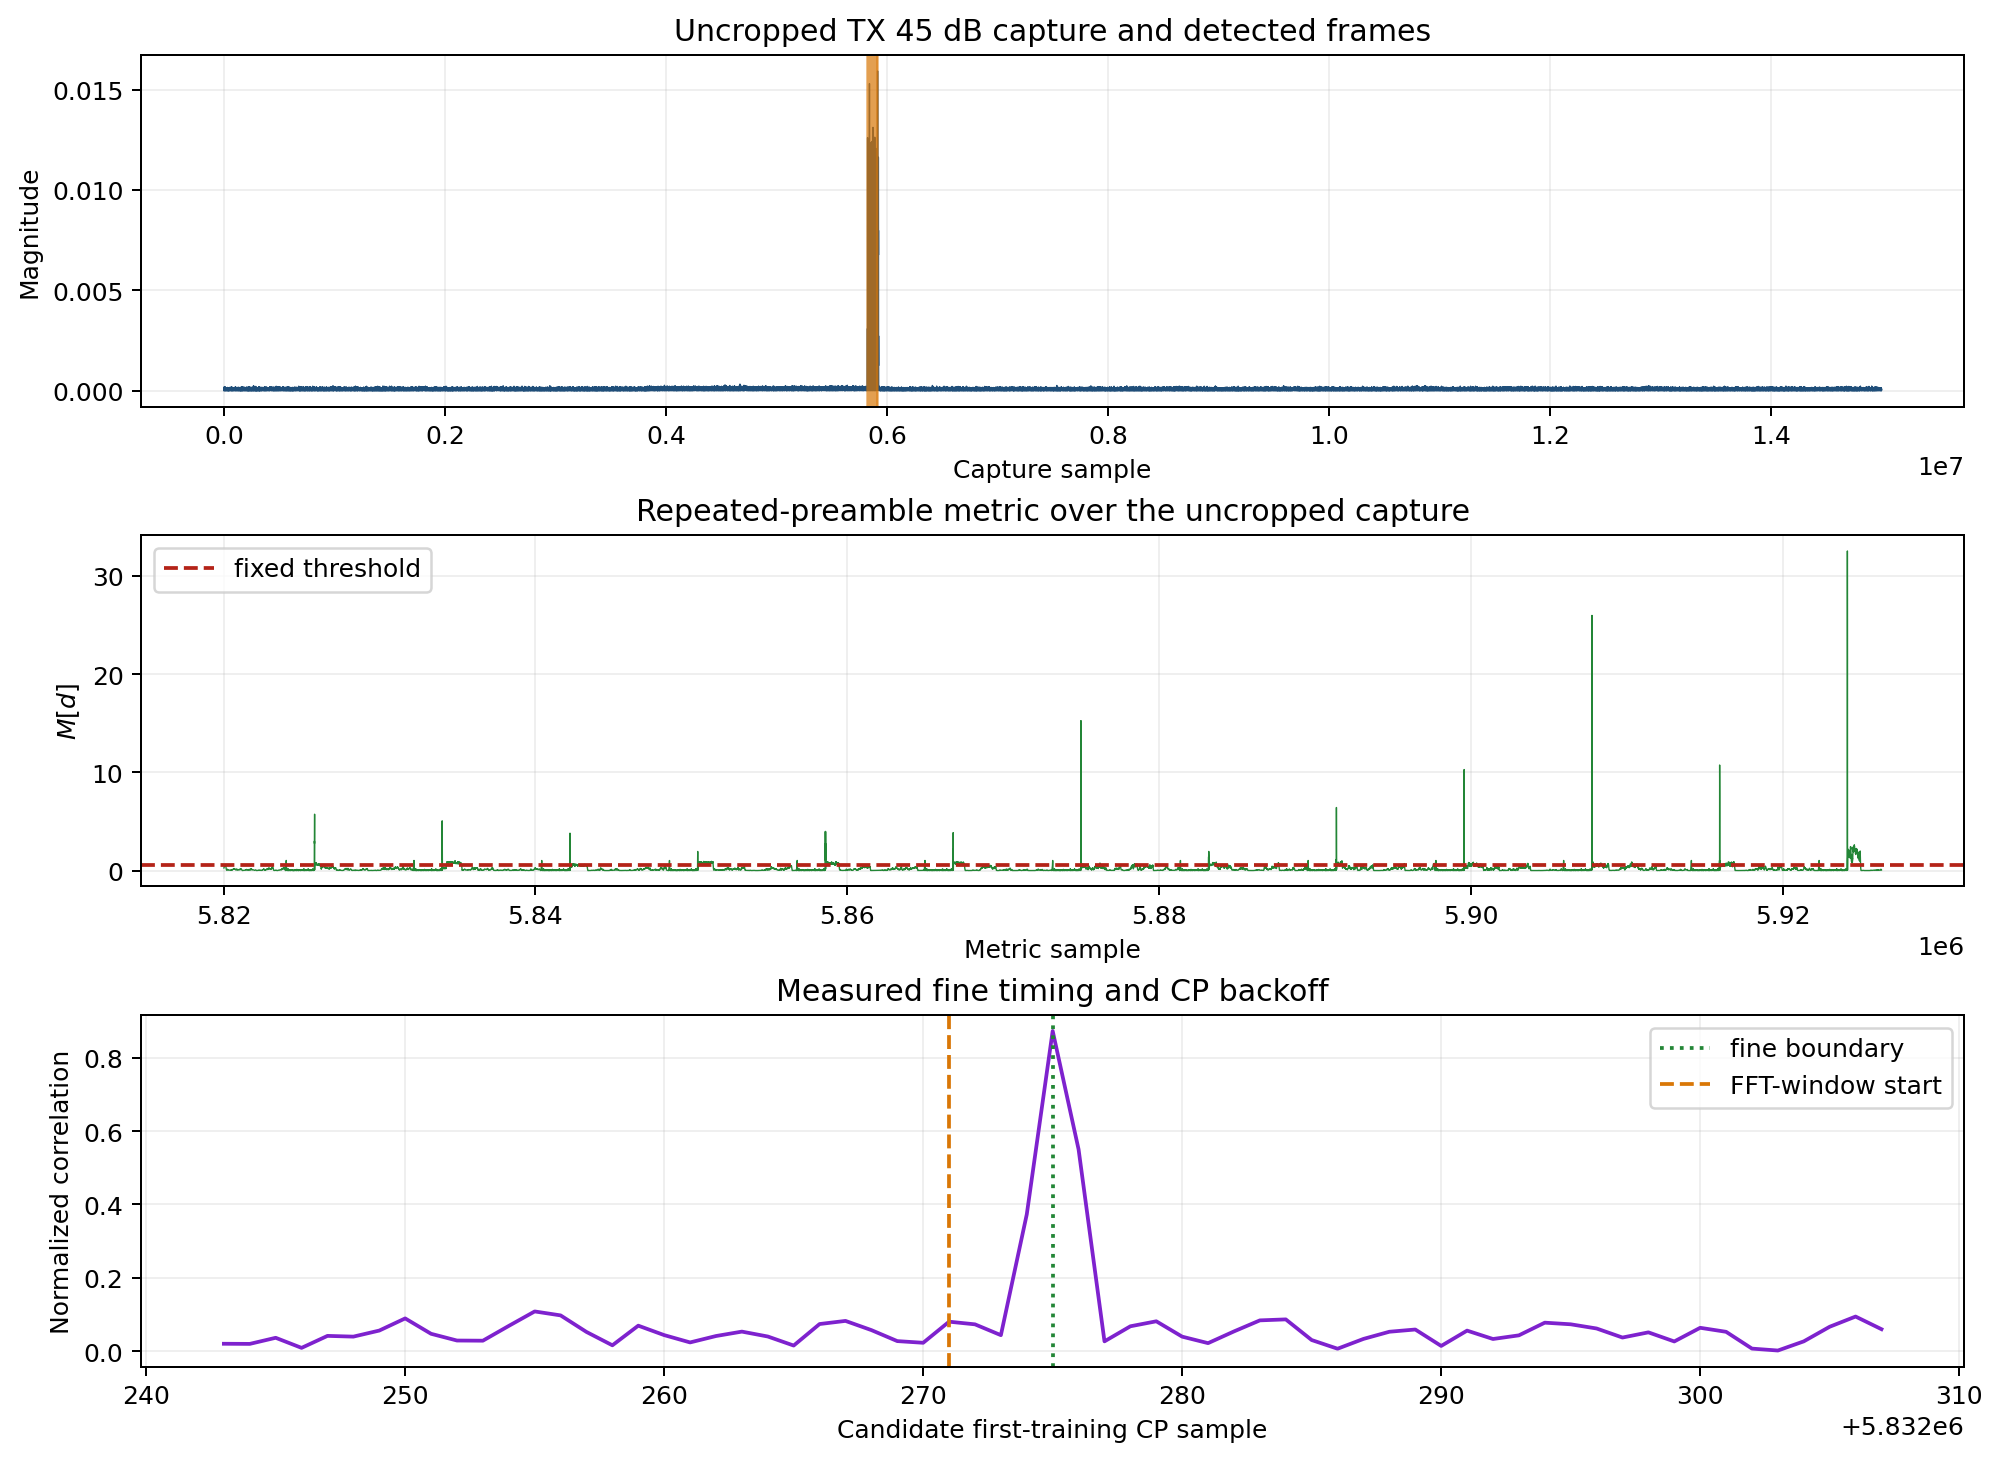

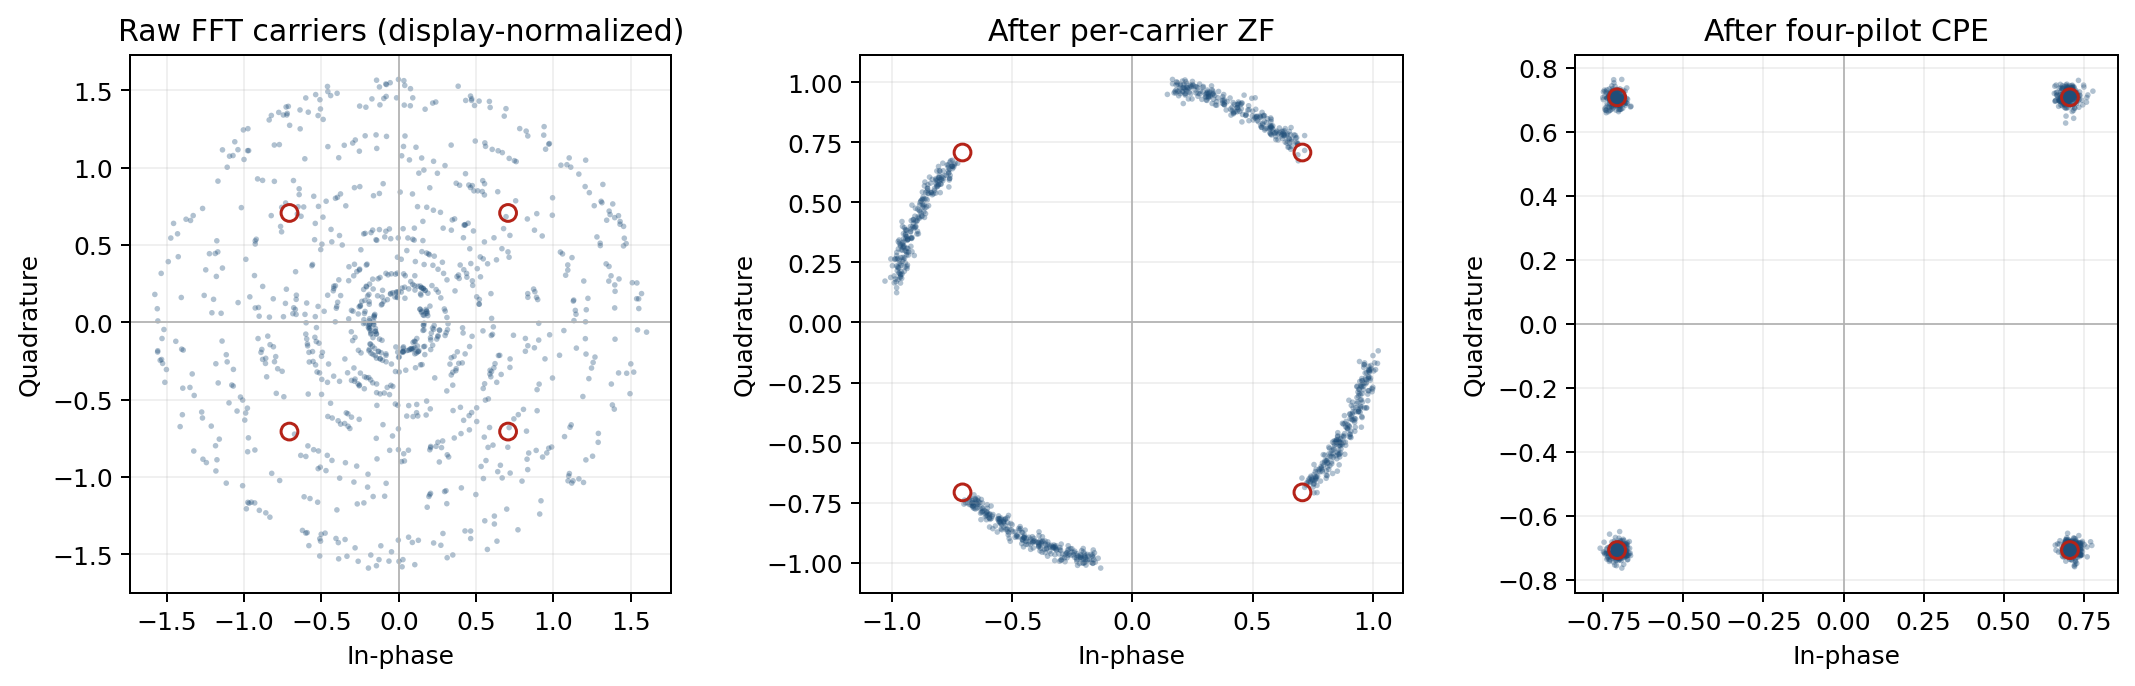

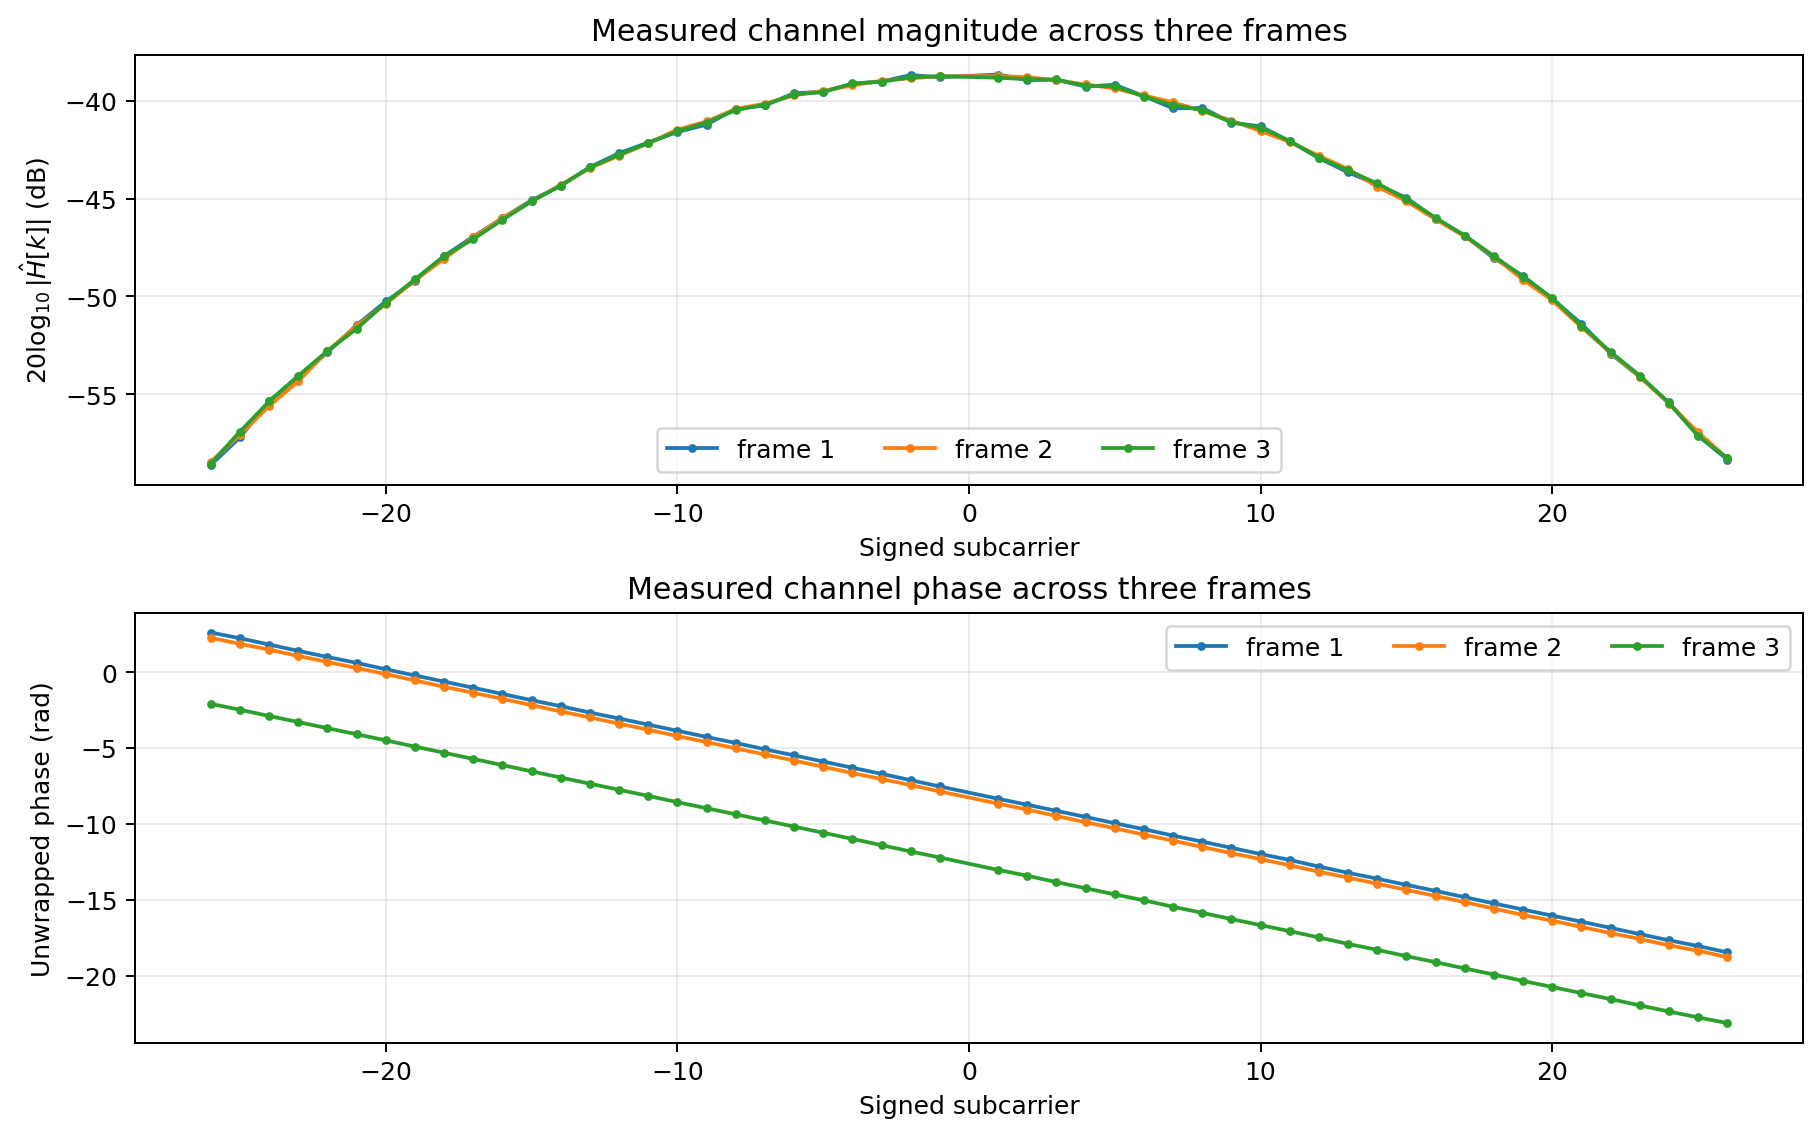

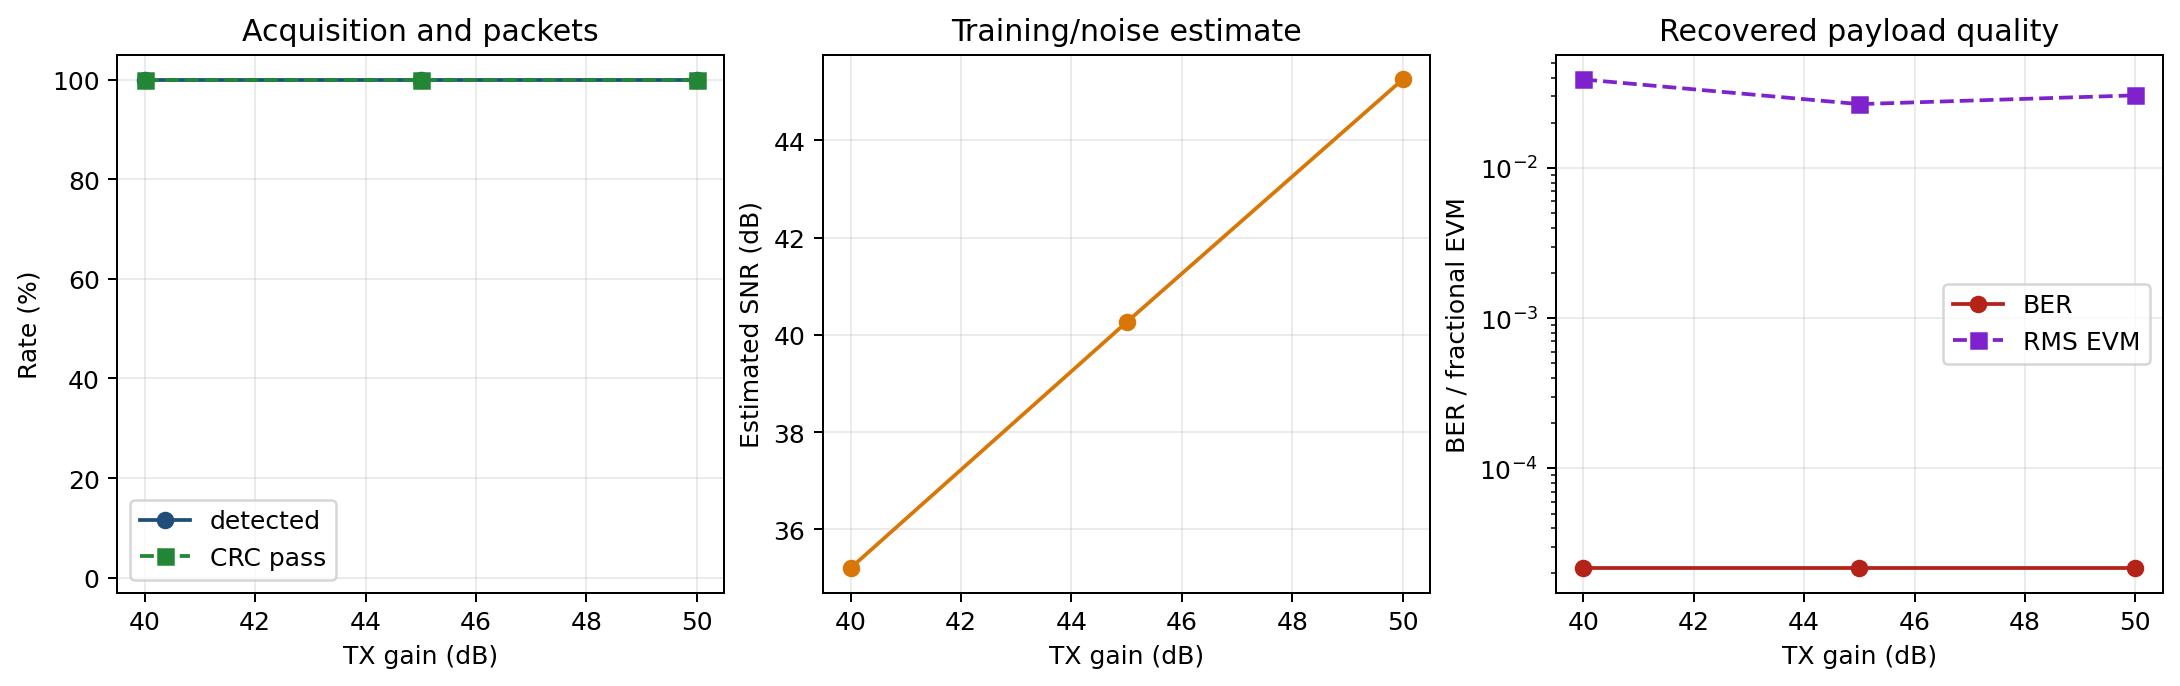

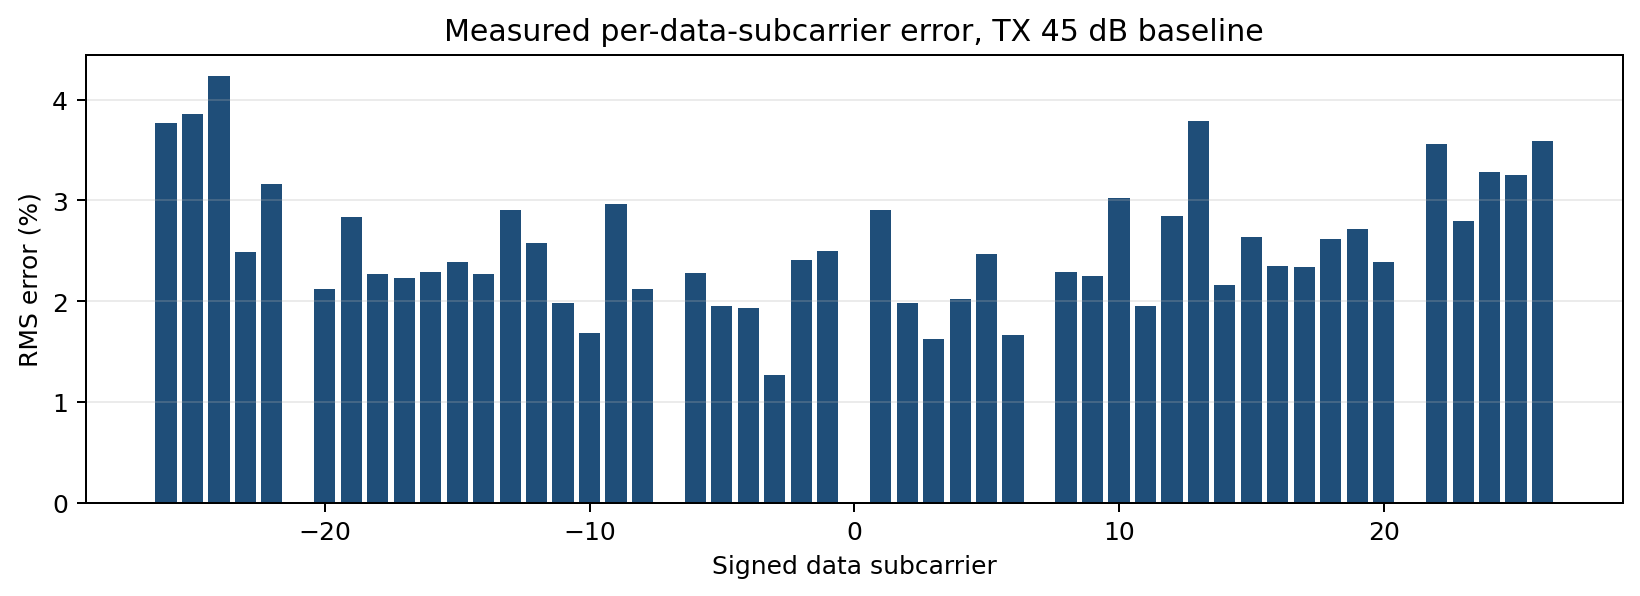

In [9]:
for name in ('task4_hardware_acquisition', 'task4_hardware_constellations', 'task4_hardware_channel_estimates', 'task4_hardware_gain_metrics', 'task4_hardware_subcarrier_error'):
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))


In [10]:
baseline_gain = tx_gains_db[len(tx_gains_db)//2]
baseline = hardware["gain_results"][f"tx{baseline_gain}"]["aggregate"]
analyzed_frames = baseline["analyzed_frames"]
expected_frames = 12

baseline_detection_rate = analyzed_frames / expected_frames
print("baseline detection rate:", baseline_detection_rate)


baseline detection rate: 1.0


## Report work


<span style="color:#165696"><b>Report.</b> Interpret the measured channel magnitude and phase across subcarriers. </span>

The measured channel magnitude shows a smooth frequency-selective response across the OFDM subcarriers. The channel gain is highest near the center subcarriers (approximately −39 dB) and gradually decreases toward the band edges (approximately −58 dB), indicating that the transmitted signal experiences greater attenuation at the outer frequencies. The nearly identical magnitude responses for the three frames demonstrate that the channel remained stable during the measurement period.

The measured channel phase exhibits an approximately linear decrease with subcarrier index. This linear phase trend is consistent with a fixed propagation delay and timing offset in the channel. The phase responses of the three frames are very similar, showing that the channel characteristics were largely unchanged across the captured packets. Overall, the magnitude and phase plots indicate a stable channel with predictable frequency-dependent gain and phase behavior, which can be effectively compensated through channel estimation and equalization.

<span style="color:#165696"><b>Report.</b> Identify corrupted packets explicitly. An undetected or failed packet is not BER zero. </span>

No corrupted packets were observed for any tested transmit gain. All analyzed frames at 40 dB, 45 dB, and 50 dB were successfully detected and passed CRC, resulting in a packet error rate of 0 and a bit error rate of 0. Since there were no failed or undetected packets, no corrupted packets were identified.

<span style="color:#165696"><b>Report.</b> Explain whether increasing gain improved EVM, CRC success, and channel-power estimates without clipping. </span>

Increasing the transmit gain generally improved the signal quality measurements without causing clipping. The estimated channel power increased monotonically from $1.69\times10^{-5}$ at 40 dB to $5.40\times10^{-5}$ at 45 dB and $1.70\times10^{-4}$ at 50 dB, indicating that a stronger signal was received as gain increased. The estimated SNR also improved from $35.2$ dB to $40.3$ dB and $45.3$ dB.

The EVM improved when the gain was increased from 40 dB to 45 dB, decreasing from $3.88\%$ to $2.66\%$, indicating more accurate symbol recovery. At 50 dB, the EVM increased slightly to $3.04\%$, but it remained better than the 40 dB case. CRC performance did not improve because it was already perfect at all gain settings, with 100% packet detection, 100% CRC success, BER = 0, and PER = 0 for all analyzed frames.

No clipping was observed at any gain level, as the clipped sample count remained zero for every measurement. Therefore, increasing gain increased received power and SNR and generally improved EVM while maintaining perfect packet recovery and avoiding receiver saturation.